# Variance, Covariance, Eigenvalues and Eigenvectors

### From statistics to Principal Component Analysis (PCA)

This notebook develops the ideas step by step using a small dataset and **NumPy**, **pandas** and **Matplotlib**.

**Learning objectives**

1. Calculate and interpret sample variance and standard deviation.
2. Calculate covariance and correlation, and read a covariance matrix.
3. Understand an eigenvector as a direction preserved by a matrix transformation, and an eigenvalue as its scaling factor.
4. Compute eigenvalues and eigenvectors of a covariance matrix.
5. Understand how PCA identifies directions of maximum variance.

Run the cells from top to bottom. All datasets are generated locally, so no downloads are required.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display, Math, Markdown
from sympy import Matrix, latex

np.set_printoptions(precision=4, suppress=True)
print("NumPy version:", np.__version__)

NumPy version: 1.26.4


## 1. Variance: how much does one variable spread out?

Given observations $x_1,\ldots,x_n$ with mean $\bar{x}$, the **sample variance** is

$$s_X^2 = \frac{1}{n-1}\sum_{i=1}^n(x_i-\bar{x})^2.$$

The sample standard deviation is $s_X=\sqrt{s_X^2}$, returning the spread to the original units.

For a **population** (rather than a sample), use $N$ instead of $n-1$. NumPy uses the population denominator by default, so specify `ddof=1` for sample variance.

In [2]:
scores = np.array([60, 70, 80, 90, 100], dtype=float)

n = len(scores)
mean = scores.mean()
deviations = scores - mean
squared_deviations = deviations**2
manual_variance = squared_deviations.sum() / (n - 1)
sample_std = np.std(scores, ddof=1)

summary = pd.DataFrame({
    "Score": scores,
    "Deviation from mean": deviations,
    "Squared deviation": squared_deviations
})
display(summary)


'''print(f"Mean = {mean:.1f}")
print(f"Sample variance = {manual_variance:.1f}")
print(f"NumPy sample variance = {np.var(scores, ddof=1):.1f}")
print(f"Sample standard deviation = {np.std(scores, ddof=1):.3f}")'''

# Format the observations for LaTeX
values = "+".join(f"{x:g}" for x in scores)
deviations = "+".join(
    f"({x:g}-{mean:g})^2" for x in scores
)
squared_deviations = "+".join(
    f"{(x - mean)**2:g}" for x in scores
)

# 1. Mean
display(Math(
    rf"\bar{{x}} = \frac{{{values}}}{{{n}}} = {mean:.1f}"
))

# 2. Sample variance
display(Math(
    rf"s^2 = \frac{{{deviations}}}{{{n}-1}}"
    rf" = \frac{{{squared_deviations}}}{{{n-1}}}"
    rf" = {manual_variance:.1f}"
))

# 3. NumPy sample variance
display(Math(
    rf"\operatorname{{Var}}_{{\mathrm{{NumPy}}}}(X)"
    rf" = {np.var(scores, ddof=1):.1f}"
))

# 4. Sample standard deviation
display(Math(
    rf"s = \sqrt{{s^2}}"
    rf" = \sqrt{{{manual_variance:.1f}}}"
    rf" = {sample_std:.3f}"
))

,Score,Deviation from mean,Squared deviation
0,60.0,-20.0,400.0
1,70.0,-10.0,100.0
2,80.0,0.0,0.0
3,90.0,10.0,100.0
4,100.0,20.0,400.0


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## 2. Sample Standard Deviation

The **sample standard deviation** measures how spread out the observations in a sample are around their mean.

It is the **square root of the sample variance**, expressed in the same units as the original data.

### 2.1. Mathematical formula

$$
\boxed{s = \sqrt{\frac{\sum_{i=1}^{n}(x_i-\bar{x})^2}{n-1}}}
$$

Where:

- $s$: Sample standard deviation.
- $x_i$: Individual observation.
- $\bar{x}$: Sample mean.
- $n$: Number of observations.
- $n-1$: Degrees of freedom (Bessel's correction).

### 2.2. Worked example

Consider five exam scores:

$$
X = [60,70,80,90,100]
$$

**Step 1: Calculate the sample mean**

$$
\bar{x}=\frac{60+70+80+90+100}{5}=80
$$

**Step 2: Calculate the squared deviations**

| Score | Deviation $(x_i-\bar{x})$ | Squared deviation $(x_i-\bar{x})^2$ |
|---|---|---|
| 60 | -20 | 400 |
| 70 | -10 | 100 |
| 80 | 0 | 0 |
| 90 | 10 | 100 |
| 100 | 20 | 400 |
| **Total** | **0** | **1000** |

**Step 3: Calculate the sample variance**

$$
s^2=\frac{1000}{5-1}=\boxed{250}
$$

**Step 4: Calculate the sample standard deviation**

$$
s=\sqrt{250}=\boxed{15.81}
$$

The sample standard deviation is approximately **15.81 points**.

### 2.3. Sample vs Population Standard Deviation

**Sample standard deviation:**

$$
s=\sqrt{\frac{\sum_{i=1}^{n}(x_i-\bar{x})^2}{n-1}}
$$

**Population standard deviation:**

$$
\sigma=\sqrt{\frac{\sum_{i=1}^{N}(x_i-\mu)^2}{N}}
$$

| Property | Sample | Population |
|---|---|---|
| Symbol | $s$ | $\sigma$ |
| Denominator | $n-1$ | $N$ |
| Purpose | Estimate population variability | Describe the entire population |
| Example result | 15.81 | 14.14 |

### 2.4. Why divide by $n-1$?

When calculating the sample mean from the same observations, the deviations must sum to zero:

$$
\sum_{i=1}^{n}(x_i-\bar{x})=0
$$

Therefore, only $n-1$ deviations can vary independently.

Dividing by $n-1$ instead of $n$ is known as **Bessel's correction**.

It makes sample variance an unbiased estimator of population variance under independent, identically distributed sampling with finite variance.

However, the sample standard deviation itself is not generally an unbiased estimator of the population standard deviation.

### 2.5. Python implementation

```python
import numpy as np

scores = np.array([60, 70, 80, 90, 100])

# Sample variance
sample_variance = np.var(scores, ddof=1)

# Sample standard deviation
sample_std = np.std(scores, ddof=1)

# Population standard deviation
population_std = np.std(scores, ddof=0)

print(f"Sample variance: {sample_variance:.2f}")
print(f"Sample standard deviation: {sample_std:.2f}")
print(f"Population standard deviation: {population_std:.2f}")
```

Expected output:

```text
Sample variance: 250.00
Sample standard deviation: 15.81
Population standard deviation: 14.14
```

**Note:** In NumPy, `ddof=1` applies Bessel's correction by dividing by $n-1$. The default `ddof=0` divides by $n$.

### 2.6. Variance vs Standard Deviation

| Property | Variance | Standard deviation |
|---|---|---|
| Measures | Spread around the mean | Spread around the mean |
| Formula | $s^2$ | $\sqrt{s^2}$ |
| Units | Squared original units | Original units |
| Example | 250 points² | 15.81 points |

**Key takeaway:**

$$
\boxed{\text{Standard Deviation}=\sqrt{\text{Variance}}}
$$

Standard deviation is generally easier to interpret because it uses the same units as the original observations.


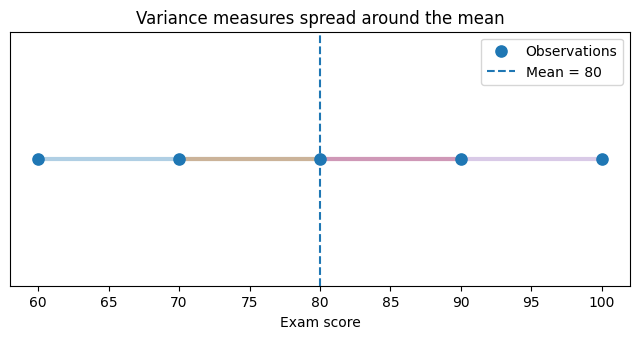

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.3))
ax.scatter(scores, np.zeros_like(scores), s=65, zorder=3, label="Observations")
ax.axvline(mean, linestyle="--", label=f"Mean = {mean:.0f}")
for x in scores:
    ax.plot([mean, x], [0, 0], alpha=0.35, linewidth=3)
ax.set(xlabel="Exam score", yticks=[], title="Variance measures spread around the mean")
ax.legend()
plt.show()

## 3. Covariance: how do two variables move together?

The **sample covariance** of variables $X$ and $Y$ is

$$\operatorname{Cov}(X,Y)=\frac{1}{n-1}\sum_{i=1}^n(x_i-\bar{x})(y_i-\bar{y}).$$

- **Positive:** as one variable increases, the other tends to increase.
- **Negative:** as one increases, the other tends to decrease.
- **Near zero:** little *linear* co-movement; nonlinear relationships can still exist.

Notice: $\operatorname{Var}(X)=\operatorname{Cov}(X,X)$.

In [4]:
hours = np.array([1, 2, 3, 4, 5], dtype=float)
exam_scores = np.array([50, 60, 70, 80, 90], dtype=float)

df = pd.DataFrame({
    "Study Hours": hours,
    "Exam Scores": exam_scores
})

display(df)

df.describe()

,Study Hours,Exam Scores
0,1.0,50.0
1,2.0,60.0
2,3.0,70.0
3,4.0,80.0
4,5.0,90.0


,Study Hours,Exam Scores
count,5.000000,5.000000
mean,3.000000,70.000000
std,1.581139,15.811388
min,1.000000,50.000000
25%,2.000000,60.000000
50%,3.000000,70.000000
75%,4.000000,80.000000
max,5.000000,90.000000


In [5]:
products = (hours - hours.mean()) * (exam_scores - exam_scores.mean())
manual_covariance = products.sum() / (len(hours)-1)
calculation = pd.DataFrame({
    "Hours": hours,
    "Score": exam_scores,
    "Hours deviation": hours-hours.mean(),
    "Score deviation": exam_scores-exam_scores.mean(),
    "Product": products
})
display(calculation)

'''print("Sample variance of hours:", np.var(hours, ddof=1))
print("Sample variance of scores:", np.var(exam_scores, ddof=1))
print("Sample covariance:", manual_covariance)'''




# Helper function to format values for LaTeX
def latex_sum(values):
    return " + ".join(f"{v:g}" for v in values)

n = len(hours)

hours_mean = hours.mean()
scores_mean = exam_scores.mean()

hours_deviations = hours - hours_mean
scores_deviations = exam_scores - scores_mean

hours_squared = hours_deviations**2
scores_squared = scores_deviations**2

n = len(hours)

# 1. Mean of study hours
hours_mean = hours.mean()
hours_values = " + ".join(f"{x:g}" for x in hours)

display(Math(
    rf"\bar{{x}}_{{\mathrm{{hours}}}}"
    rf" = \frac{{{hours_values}}}{{{n}}}"
    rf" = {hours_mean:.1f}"
))

# 2. Mean of exam scores
scores_mean = exam_scores.mean()
scores_values = " + ".join(f"{x:g}" for x in exam_scores)

display(Math(
    rf"\bar{{x}}_{{\mathrm{{scores}}}}"
    rf" = \frac{{{scores_values}}}{{{n}}}"
    rf" = {scores_mean:.1f}"
))

# Helper function to show deviations before squaring
def latex_squared_deviations(data, mean):
    return " + ".join(
        rf"({x:g} - {mean:g})^2"
        for x in data
    )

# 3. Sample variance of hours
display(Math(
    rf"\begin{{aligned}}"
    rf"s_{{\mathrm{{hours}}}}^2"
    rf" &= \frac{{{latex_squared_deviations(hours, hours_mean)}}}{{{n}-1}} \\[6pt]"
    rf" &= \frac{{{latex_sum(hours_squared)}}}{{{n-1}}}"
    rf" = \frac{{{hours_squared.sum():g}}}{{{n-1}}}"
    rf" = \boxed{{{np.var(hours, ddof=1):g}}}"
    rf"\end{{aligned}}"
))

# 4. Sample variance of scores
display(Math(
    rf"\begin{{aligned}}"
    rf"s_{{\mathrm{{scores}}}}^2"
    rf" &= \frac{{{latex_squared_deviations(exam_scores, scores_mean)}}}{{{n}-1}} \\[6pt]"
    rf" &= \frac{{{latex_sum(scores_squared)}}}{{{n-1}}}"
    rf" = \frac{{{scores_squared.sum():g}}}{{{n-1}}}"
    rf" = \boxed{{{np.var(exam_scores, ddof=1):g}}}"
    rf"\end{{aligned}}"
))

# Sample standard deviations
hours_std = np.std(hours, ddof=1)
scores_std = np.std(exam_scores, ddof=1)

# 5. Standard deviation of study hours
display(Math(
    rf"\begin{{aligned}}"
    rf"s_{{\mathrm{{hours}}}}"
    rf" &= \sqrt{{s_{{\mathrm{{hours}}}}^2}}"
    rf" = \sqrt{{{np.var(hours, ddof=1):g}}}"
    rf" = \boxed{{{hours_std:.3f}}}"
    rf"\end{{aligned}}"
))

# 6. Standard deviation of exam scores
display(Math(
    rf"\begin{{aligned}}"
    rf"s_{{\mathrm{{scores}}}}"
    rf" &= \sqrt{{s_{{\mathrm{{scores}}}}^2}}"
    rf" = \sqrt{{{np.var(exam_scores, ddof=1):g}}}"
    rf" = \boxed{{{scores_std:.3f}}}"
    rf"\end{{aligned}}"
))

# 7. Sample covariance
# Show each pair of deviations multiplied together
covariance_terms = " + ".join(
    rf"({h:g}-{hours_mean:g})({s:g}-{scores_mean:g})"
    for h, s in zip(hours, exam_scores)
)

display(Math(
    r"\operatorname{Cov}(X,Y)"
    r" = \frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}{n-1}"
))

display(Math(
    rf"\begin{{aligned}}"
    rf"\operatorname{{Cov}}(\mathrm{{hours}},\mathrm{{scores}})"
    rf" &= \frac{{{covariance_terms}}}{{{n}-1}} \\[6pt]"
    rf" &= \frac{{{latex_sum(products)}}}{{{n-1}}}"
    rf" = \frac{{{products.sum():g}}}{{{n-1}}}"
    rf" = \boxed{{{manual_covariance:g}}}"
    rf"\end{{aligned}}"
))



,Hours,Score,Hours deviation,Score deviation,Product
0,1.0,50.0,-2.0,-20.0,40.0
1,2.0,60.0,-1.0,-10.0,10.0
2,3.0,70.0,0.0,0.0,0.0
3,4.0,80.0,1.0,10.0,10.0
4,5.0,90.0,2.0,20.0,40.0


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

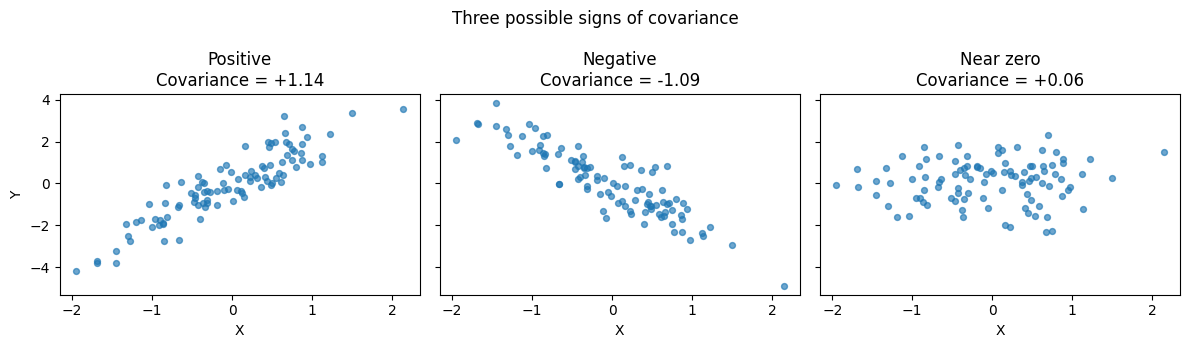

In [6]:
rng = np.random.default_rng(42)
x = rng.normal(size=100)
relationships = { # This contains the 'y' values for each relationship
    "Positive": 1.8*x + rng.normal(scale=.7, size=len(x)),
    "Negative": -1.8*x + rng.normal(scale=.7, size=len(x)),
    "Near zero": rng.normal(size=len(x))
}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharex=True, sharey=True)
for ax, (name, y) in zip(axes, relationships.items()):
    ax.scatter(x, y, alpha=.65, s=18)
    covariance = np.cov(x, y)[0, 1]
    ax.set_title(f"{name}\nCovariance = {covariance:+.2f}")
    ax.set_xlabel("X")
axes[0].set_ylabel("Y")
fig.suptitle("Three possible signs of covariance")
fig.tight_layout()
plt.show()

## 4. Covariance matrix and correlation

For two variables the sample covariance matrix is

$$
\mathbf{S}=\begin{bmatrix}
\operatorname{Var}(X) & \operatorname{Cov}(X,Y)\\
\operatorname{Cov}(Y,X) & \operatorname{Var}(Y)
\end{bmatrix}.
$$

The diagonal contains **variances**. Off-diagonal terms contain **covariances**. The matrix is symmetric.

Covariance depends on units and scales, so correlation standardises it:

$$r_{XY}=\frac{\operatorname{Cov}(X,Y)}{s_Xs_Y},\qquad -1\le r_{XY}\le1.$$

A correlation of zero does **not** prove independence.

### Pearson's correlation

Pearson's correlation coefficient divides the covariance by the product of the standard deviations of the two variables, not by their variances.

$$
\boxed{r_{XY}=\frac{\operatorname{Cov}(X,Y)}{s_Xs_Y}}
$$

Since standard deviation is the square root of variance:

$$
s_X=\sqrt{\operatorname{Var}(X)}
$$

We can also express correlation as:

$$
\boxed{r_{XY}=\frac{\operatorname{Cov}(X,Y)}{\sqrt{\operatorname{Var}(X)\operatorname{Var}(Y)}}}
$$

These two formulas are mathematically equivalent.

### Why standard deviation instead of variance?

Because the purpose of correlation is to remove the units and scales of the original variables.

Let's use your previous example:

| Statistic | Study hours | Exam scores |
|---|---:|---:|
| Sample variance | 2.5 | 250 |
| Sample standard deviation | 1.581 | 15.811 |
| Sample covariance (hours, scores) | **25** | |

The covariance has units of hours × score points.

Dividing by the standard deviations ($s_{x} \times s_{y}$):

$$
r=\frac{\operatorname{Cov}(hours,scores)}{s_{hours} \times s_{scores}}=\frac{25}{\sqrt{2.5}\sqrt{250}}=\frac{25}{\sqrt{2.5\times 250}}=\frac{25}{25}=\boxed{1}
$$

The units cancel:

$$
\frac{\text{hours}\times\text{points}}{\text{hours}\times\text{points}}=1
$$

The result is dimensionless and always falls between -1 and +1, provided both variables have non-zero standard deviations.

If you divided by the product of the variances instead ($s_{x}^2 \times s_{y}^2$), you would not obtain a scale-independent correlation coefficient.

In [7]:
data = pd.DataFrame({"Study hours": hours, "Exam score": exam_scores})
print("Sample covariance matrix:")
display(data.cov())
print("Correlation matrix:")
display(data.corr())
print("np.cov agrees with pandas:\n", np.cov(hours, exam_scores))
print("np.corrcoef agrees with pandas:\n", np.corrcoef(hours, exam_scores))

Sample covariance matrix:


,Study hours,Exam score
Study hours,2.5,25.0
Exam score,25.0,250.0


Correlation matrix:


,Study hours,Exam score
Study hours,1.0,1.0
Exam score,1.0,1.0


np.cov agrees with pandas:
 [[  2.5  25. ]
 [ 25.  250. ]]
np.corrcoef agrees with pandas:
 [[1. 1.]
 [1. 1.]]


In [8]:
# Sample covariance matrix
cov_matrix = np.cov(hours, exam_scores)

# Standard deviations from the covariance matrix
std = np.sqrt(np.diag(cov_matrix))

# Convert covariance matrix to correlation matrix
corr_from_cov = cov_matrix / np.outer(std, std)

print("Covariance matrix:")
print(cov_matrix)

print("\nCorrelation calculated from covariance:")
print(corr_from_cov)

print("\nCorrelation calculated directly:")
print(np.corrcoef(hours, exam_scores))

# Verify equivalence
print("\nBoth methods agree:",
      np.allclose(corr_from_cov, np.corrcoef(hours, exam_scores)))

Covariance matrix:
[[  2.5  25. ]
 [ 25.  250. ]]

Correlation calculated from covariance:
[[1. 1.]
 [1. 1.]]

Correlation calculated directly:
[[1. 1.]
 [1. 1.]]

Both methods agree: True


In [9]:
# Calculate covariance and correlation matrices
cov_matrix = np.cov(hours, exam_scores)
corr_matrix = np.corrcoef(hours, exam_scores)

# Calculate standard deviations
std = np.sqrt(np.diag(cov_matrix))

# Convert a NumPy matrix to LaTeX
def latex_matrix(matrix, precision=3):
    rows = [
        " & ".join(f"{v:.{precision}f}" for v in row)
        for row in matrix
    ]
    return r"\begin{bmatrix}" + r" \\ ".join(rows) + r"\end{bmatrix}"

# Build the intermediate matrix using covariance / standard deviations
fractions = [
    [
        rf"\frac{{{cov_matrix[i, j]:g}}}"
        rf"{{\sqrt{{{cov_matrix[i, i]:g}}}"
        rf"\sqrt{{{cov_matrix[j, j]:g}}}}}"
        for j in range(2)
    ]
    for i in range(2)
]

fractions_latex = (
    r"\begin{bmatrix}"
    + r" \\ ".join(" & ".join(row) for row in fractions)
    + r"\end{bmatrix}"
)

# Display the full derivation
display(Math(
    rf"\begin{{aligned}}"
    rf"\mathbf{{R}}"
    rf" &= \begin{{bmatrix}}"
    rf"\frac{{s_X^2}}{{s_Xs_X}} & \frac{{s_{{XY}}}}{{s_Xs_Y}} \\"
    rf"\frac{{s_{{XY}}}}{{s_Ys_X}} & \frac{{s_Y^2}}{{s_Ys_Y}}"
    rf"\end{{bmatrix}} \\[12pt]"
    rf" &= {fractions_latex} \\[12pt]"
    rf" &= \boxed{{{latex_matrix(corr_matrix)}}}"
    rf"\end{{aligned}}"
))

<IPython.core.display.Math object>

In [10]:
# Convert covariance to correlation manually
manual_corr_matrix = cov_matrix / np.outer(std, std)

# Verify against NumPy
assert np.allclose(manual_corr_matrix, corr_matrix)


### Covariance Matrix vs Correlation Matrix

Both the **covariance matrix** and the **correlation matrix** describe relationships between variables. However, they represent these relationships differently.

#### 1. Covariance Matrix

For two variables $X$ and $Y$, the covariance matrix is defined as:

$$
S =
\begin{bmatrix}
\operatorname{Var}(X) & \operatorname{Cov}(X,Y) \\
\operatorname{Cov}(Y,X) & \operatorname{Var}(Y)
\end{bmatrix}
$$

- **Diagonal:** Variance of each variable.
- **Off-diagonal:** Covariance between different variables.

**Important property: Covariance is symmetric.**

$$
\boxed{\operatorname{Cov}(X,Y)=\operatorname{Cov}(Y,X)}
$$

This follows from the sample covariance formula:

$$
\operatorname{Cov}(X,Y)
=
\frac{1}{n-1}
\sum_{i=1}^{n}
(x_i-\bar{x})(y_i-\bar{y})
$$

Since multiplication is commutative, exchanging $X$ and $Y$ does not change the result.

Therefore, the covariance matrix can also be expressed as:

$$
S =
\begin{bmatrix}
s_X^2 & s_{XY} \\
s_{XY} & s_Y^2
\end{bmatrix}
$$

And it is always **symmetric**:

$$
\boxed{S=S^T}
$$

#### 2. Correlation Matrix

The correlation matrix contains the **Pearson correlation coefficients** between variables.

For two variables $X$ and $Y$:

$$
R =
\begin{bmatrix}
r_{XX} & r_{XY} \\
r_{YX} & r_{YY}
\end{bmatrix}
$$

The Pearson correlation coefficient is defined as:

$$
r_{XY} =
\frac{\operatorname{Cov}(X,Y)}{s_Xs_Y}
$$

Where $s_X$ and $s_Y$ are the standard deviations of $X$ and $Y$.

- **Diagonal:** Always 1 for variables with nonzero variance, because each variable is perfectly correlated with itself.
- **Off-diagonal:** Correlation between different variables, ranging from -1 to +1.

For the diagonal elements:

$$
\begin{aligned}
r_{XX}
&=\frac{\operatorname{Cov}(X,X)}{s_Xs_X}\\[6pt]
&=\frac{\operatorname{Var}(X)}{s_X^2}\\[6pt]
&=\boxed{1}
\end{aligned}
$$

Similarly:

$$
r_{YY}=1
$$

**Important property: Correlation is also symmetric.**

$$
\boxed{r_{XY}=r_{YX}}
$$

Therefore, the correlation matrix can be written as:

$$
R =
\begin{bmatrix}
1 & r_{XY} \\
r_{XY} & 1
\end{bmatrix}
$$

And:

$$
\boxed{R=R^T}
$$

**Important:** If a variable has zero variance, its correlation is undefined because its standard deviation is zero.

#### 3. Relationship Between the Two Matrices

The correlation matrix is obtained by standardising the covariance matrix using the standard deviations of the variables:

$$
\boxed{
r_{XY} =
\frac{\operatorname{Cov}(X,Y)}{s_Xs_Y}
}
$$

In matrix notation:

$$
\boxed{R=D^{-1}SD^{-1}}
$$

Where:

$$
D =
\begin{bmatrix}
s_X & 0 \\
0 & s_Y
\end{bmatrix}
$$

- $R$ is the correlation matrix.
- $S$ is the covariance matrix.
- $D$ is the diagonal matrix containing the standard deviations.
- $D^{-1}$ is the inverse of $D$.


This relationship requires nonzero standard deviations.

For example, consider the covariance matrix:

$$
S =
\begin{bmatrix}
4 & 2 \\
2 & 9
\end{bmatrix}
$$

The standard deviations are:

$$
s_X=\sqrt{4}=2,
\qquad
s_Y=\sqrt{9}=3
$$

Therefore:

$$
r_{XY}=\frac{2}{2\times3}=\frac{1}{3}
$$

And the correlation matrix becomes:

$$
R =
\begin{bmatrix}
1 & \frac{1}{3} \\
\frac{1}{3} & 1
\end{bmatrix}
$$

#### 4. Key Differences

| Property | Covariance Matrix | Correlation Matrix |
|---|---|---|
| Diagonal | Variances | Ones (1) |
| Off-diagonal | Covariances | Correlation coefficients |
| Units | Depends on the variables | Dimensionless |
| Range | Unbounded in general | Between -1 and +1 |
| Symmetric | Yes | Yes |
| Used in PCA | PCA on original feature scales | PCA on standardised features |

**Key takeaway:** The correlation matrix is the covariance matrix of variables standardised to have zero mean and unit variance.

Both matrices are symmetric, but the correlation matrix removes differences caused by measurement units and individual feature scales.


In [11]:
import numpy as np

# S is the covariance matrix
S = np.array([[4, 2], [2, 9]])

# Standard deviations from covariance diagonal
D = np.diag(np.sqrt(np.diag(S)))

# diagonal elements
diag = np.diag(S)
print(f"The diagonal elements of the covariance matrix are {diag} which represent the variances.")
diag_sqr_root = np.sqrt(diag)
print(f"The diagonal elements of the correlation matrix are {diag_sqr_root} which represent the standard deviations.")

# Inverse of D
D_inv = np.linalg.inv(D)

# Correlation matrix
R = D_inv @ S @ D_inv

print(f"The correlation matrix is:\n{R}")

The diagonal elements of the covariance matrix are [4 9] which represent the variances.
The diagonal elements of the correlation matrix are [2. 3.] which represent the standard deviations.
The correlation matrix is:
[[1.     0.3333]
 [0.3333 1.    ]]



### Why doesn't zero correlation prove independence?

**Pearson correlation measures the strength and direction of a linear relationship between two variables.**

However, **independence** means that knowing the value of one variable provides no information about the probability distribution of the other.

Therefore:

- **Zero correlation** means there is no linear association between the variables.
- **Independence** means there is no statistical dependence between the variables, whether linear or nonlinear.

#### Example: A nonlinear relationship

Consider two variables:

$$
X=[-2,-1,0,1,2]
$$

$$
Y=X^2=[4,1,0,1,4]
$$

Although $Y$ is completely determined by $X$, their Pearson correlation is zero.

**Step 1: Calculate the means**

$$
\bar{X}=\frac{-2-1+0+1+2}{5}=0
$$

$$
\bar{Y}=\frac{4+1+0+1+4}{5}=2
$$

**Step 2: Calculate the sample covariance**

$$
\begin{aligned}
\operatorname{Cov}(X,Y)
&=\frac{\sum_{i=1}^{n}(x_i-\bar{X})(y_i-\bar{Y})}{n-1}\\[6pt]
&=\frac{(-2)(2)+(-1)(-1)+(0)(-2)+(1)(-1)+(2)(2)}{5-1}\\[6pt]
&=\frac{-4+1+0-1+4}{4}\\[6pt]
&=\boxed{0}
\end{aligned}
$$

**Step 3: Calculate Pearson correlation**

$$
r_{XY}=\frac{\operatorname{Cov}(X,Y)}{s_Xs_Y}
=\frac{0}{s_Xs_Y}
=\boxed{0}
$$

The correlation is zero because the positive and negative contributions to the covariance cancel each other.

Nevertheless, the variables are **not independent**, because $Y$ is completely determined by $X$ through the relationship $Y=X^2$.

#### Independence vs zero correlation

| Concept | Interpretation |
|---|---|
| Positive correlation | Variables tend to increase together |
| Negative correlation | One variable tends to decrease as the other increases |
| Zero correlation | No linear association |
| Independence | Knowing one variable provides no information about the distribution of the other |

**Important mathematical property:**

$$
X\perp Y \implies \operatorname{Cov}(X,Y)=0
$$

However: <!-- This does not display well in the PDF: \centernot\implies  NEITHER \centernot\implies I will apply a postprocessing trick in the PDF conversion. -->

$$
\operatorname{Cov}(X,Y)=0 \centernot\implies X\perp Y
$$

The first implication assumes that the covariance exists. Zero covariance is equivalent to zero Pearson correlation when both standard deviations are finite and non-zero.

**Exception:** For variables with a **joint Gaussian distribution**, zero correlation does imply independence.

NB: The symbol $\perp$ means perpendicular in geometry, but in statistics it is commonly used to represent independence.

#### Key takeaway

**Zero correlation does not necessarily mean there is no relationship.** It only means Pearson's correlation coefficient does not detect a linear relationship.

This is important in machine learning because features with zero or near-zero linear correlation may still contain useful information for nonlinear models such as decision trees and random forests.


In [12]:
# Dataset
x = np.array([-2, -1, 0, 1, 2], dtype=float)
y = x**2

df = pd.DataFrame({
    "X": x,
    "Y = X²": y
})

display(df)

print("Sample covariance:", np.cov(x, y)[0, 1])
print("Pearson correlation:", np.corrcoef(x, y)[0, 1])

,X,Y = X²
0,-2.0,4.0
1,-1.0,1.0
2,0.0,0.0
3,1.0,1.0
4,2.0,4.0


Sample covariance: 0.0
Pearson correlation: 0.0


,X,Y = X²
0,-2,4
1,-1,1
2,0,0
3,1,1
4,2,4


<IPython.core.display.Math object>

<IPython.core.display.Math object>

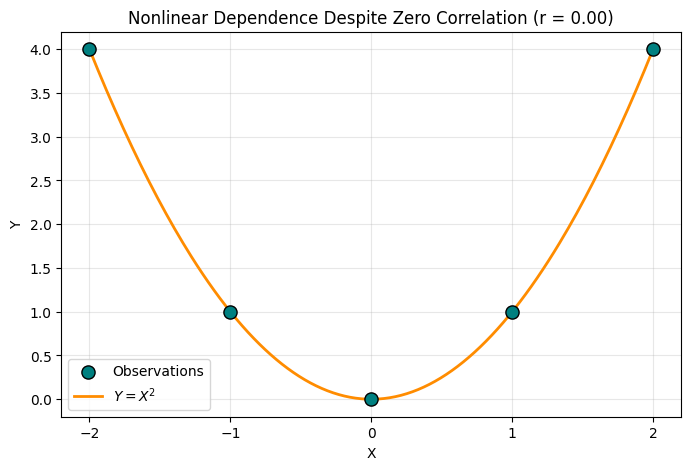

In [13]:
# Display DataFrame
#display(df.style.format("{:.0f}"))

def display_dataframe(df, precision=0, show_index=True):
    """
    Display a DataFrame in Jupyter and export it to LaTeX.

    Jupyter uses the HTML representation.
    nbconvert uses the LaTeX representation.

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame to display.
    precision : int
        Number of decimal places (default: 0).
    show_index : bool
        Whether to include the DataFrame index.
    """

    number_format = f"{{:.{precision}f}}"

    # HTML representation for Jupyter
    html_output = (
        df.style
        .format(number_format)
        .hide(axis="index") if not show_index
        else df.style.format(number_format)
    ).to_html()

    # LaTeX representation for PDF export
    latex_output = df.to_latex(
        index=show_index,
        float_format=f"%.{precision}f"
    )

    # One output containing both representations
    display({
        "text/html": html_output,
        "text/latex": latex_output
    }, raw=True)

display_dataframe(df)

# Calculate covariance and correlation
covariance = np.cov(x, y)[0, 1]
correlation = np.corrcoef(x, y)[0, 1]

# Display mathematical results
display(Math(
    rf"\operatorname{{Cov}}(X,Y) = \boxed{{{covariance:.3f}}}"
))

display(Math(
    rf"r_{{XY}} = \boxed{{{correlation:.3f}}}"
))

# Generate a smooth parabola
x_curve = np.linspace(x.min(), x.max(), 200)
y_curve = x_curve**2

# Plot
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    x, y,
    s=90,
    color="teal",
    edgecolor="black",
    zorder=3,
    label="Observations"
)

ax.plot(
    x_curve, y_curve,
    color="darkorange",
    linewidth=2,
    label=r"$Y = X^2$"
)

ax.set(
    title=f"Nonlinear Dependence Despite Zero Correlation (r = {correlation:.2f})",
    xlabel="X",
    ylabel="Y"
)

ax.set_xticks(x)
ax.grid(True, alpha=0.3)
ax.legend()

plt.show()


## 5. Eigenvectors and eigenvalues: directions and scaling

For a square matrix $\mathbf A$, an **eigenvector** $\mathbf v\ne \mathbf 0$ and **eigenvalue** $\lambda$ satisfy

$$\boxed{\mathbf A\mathbf v=\lambda\mathbf v}.$$

In words: transforming $\mathbf v$ by $\mathbf A$ changes its **length** and possibly its sign, but not its underlying line of direction.

- $\lambda>1$: scaling/expansion along that eigenvector.
- $0<\lambda<1$: shrinking along that eigenvector.
- $\lambda<0$: the direction is also reversed.
- $\lambda=0$: the vector is mapped to zero.

For example, $\mathbf A=\left[\begin{smallmatrix}3&0\\0&1\end{smallmatrix}\right]$ stretches the horizontal axis by three while leaving the vertical axis unchanged.

In [14]:
A = np.array([[3., 0.], [0., 1.]])
eigenvalues, eigenvectors = np.linalg.eig(A)
print("Matrix A:\n", A)
print("Eigenvalues:", eigenvalues)
print("Eigenvectors (COLUMNS):\n", eigenvectors)
for i in range(2):
    v = eigenvectors[:, i]
    lam = eigenvalues[i]
    print(f"Check eigenpair {i+1}: A @ v = {A @ v}, lambda * v = {lam * v}")
    assert np.allclose(A @ v, lam*v)

Matrix A:
 [[3. 0.]
 [0. 1.]]
Eigenvalues: [3. 1.]
Eigenvectors (COLUMNS):
 [[1. 0.]
 [0. 1.]]
Check eigenpair 1: A @ v = [3. 0.], lambda * v = [3. 0.]
Check eigenpair 2: A @ v = [0. 1.], lambda * v = [0. 1.]


### 5.1. What happens when we multiply?

The fundamental eigenvalue equation is:

$$
Av=\lambda v
$$

For the first eigenvector:

$$
\begin{aligned}
A\mathbf{v}_1
&=\begin{bmatrix}3&0\\0&1\end{bmatrix}
\begin{bmatrix}1\\0\end{bmatrix}
=\begin{bmatrix}3\\0\end{bmatrix}
=3\begin{bmatrix}1\\0\end{bmatrix}
\end{aligned}
$$

For the second:

$$
\begin{aligned}
A\mathbf{v}_2
&=\begin{bmatrix}3&0\\0&1\end{bmatrix}
\begin{bmatrix}0\\1\end{bmatrix}
=\begin{bmatrix}0\\1\end{bmatrix}
=1\begin{bmatrix}0\\1\end{bmatrix}
\end{aligned}
$$

### 5.2. Visual interpretation

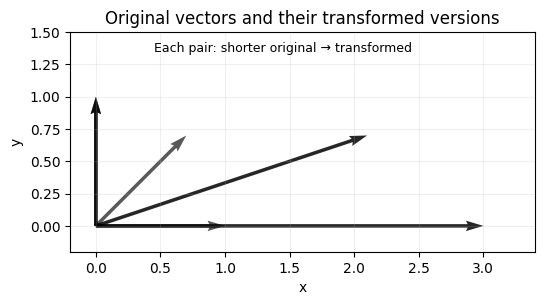

In [15]:
fig, ax = plt.subplots(figsize=(6, 5))

original_vectors = [
    np.array([1., 0.]),   # Eigenvector 1
    np.array([0., 1.]),   # Eigenvector 2
    np.array([.7, .7])    # Not an eigenvector
]

for v in original_vectors:
    transformed = A @ v
    ax.quiver(0, 0, *v, angles='xy', scale_units='xy', scale=1, alpha=.65)
    ax.quiver(0, 0, *transformed, angles='xy', scale_units='xy', scale=1, alpha=.85)
ax.set(xlim=(-.2, 3.4), ylim=(-.2, 1.5), xlabel="x", ylabel="y",
       title="Original vectors and their transformed versions")
ax.set_aspect('equal')
ax.grid(alpha=.2)
ax.text(.45, 1.35, "Each pair: shorter original → transformed", fontsize=9)
plt.show()

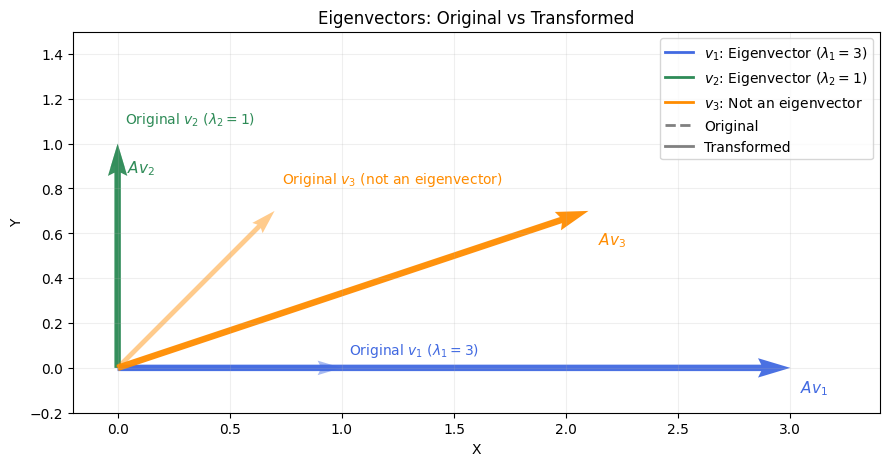

In [16]:
colors = ["royalblue", "seagreen", "darkorange"]

labels = [
    r"$v_1$ ($\lambda_1=3$)",
    r"$v_2$ ($\lambda_2=1$)",
    r"$v_3$ (not an eigenvector)"
]

fig, ax = plt.subplots(figsize=(9, 6))

for i, v in enumerate(original_vectors):
    transformed = A @ v
    color = colors[i]

    # Original vector: dashed
    ax.quiver(
        0, 0, *v,
        angles="xy", scale_units="xy", scale=1,
        color=color, alpha=0.45,
        linestyle="--", width=0.006
    )

    # Transformed vector: solid
    ax.quiver(
        0, 0, *transformed,
        angles="xy", scale_units="xy", scale=1,
        color=color, alpha=0.95, width=0.008
    )

    # Original label
    ax.annotate(
        f"Original {labels[i]}",
        xy=v,
        xytext=(5, 10 + i * 5),
        textcoords="offset points",
        color=color,
        fontsize=10
    )

    # Transformed label
    ax.annotate(
        rf"$Av_{i+1}$",
        xy=transformed,
        xytext=(7, -18 - i * 3),
        textcoords="offset points",
        color=color,
        fontsize=11,
        fontweight="bold"
    )

# Custom legend
legend_elements = [
    Line2D([0], [0], color="royalblue", lw=2,
           label=r"$v_1$: Eigenvector ($\lambda_1=3$)"),
    Line2D([0], [0], color="seagreen", lw=2,
           label=r"$v_2$: Eigenvector ($\lambda_2=1$)"),
    Line2D([0], [0], color="darkorange", lw=2,
           label=r"$v_3$: Not an eigenvector"),
    Line2D([0], [0], color="grey", lw=2, linestyle="--",
           label="Original"),
    Line2D([0], [0], color="grey", lw=2,
           label="Transformed"),
]

ax.legend(handles=legend_elements, loc="upper right")

ax.set(
    xlim=(-0.2, 3.4),
    ylim=(-0.2, 1.5),
    xlabel="X",
    ylabel="Y",
    title="Eigenvectors: Original vs Transformed"
)

ax.set_aspect("equal")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


### What the plot demonstrates

The matrix

$$
A=\begin{bmatrix}3&0\\0&1\end{bmatrix}
$$

scales the X-axis by a factor of 3 while leaving the Y-axis unchanged.

| Vector | Original | Transformed | Interpretation |
|---|---|---|---|
| $v_1$ | $(1,0)$ | $(3,0)$ | Same direction, stretched by $\lambda_1=3$ |
| $v_2$ | $(0,1)$ | $(0,1)$ | Unchanged, $\lambda_2=1$ |
| $v_3$ | $(0.7,0.7)$ | $(2.1,0.7)$ | Changes direction, so it is not an eigenvector |

**Key observations:**

- **Eigenvector $v_1$:** Its direction remains unchanged, but its magnitude is multiplied by 3.
- **Eigenvector $v_2$:** Both its direction and magnitude remain unchanged because its eigenvalue is 1.
- **Vector $v_3$:** Its direction changes because the X component is multiplied by 3 while the Y component remains unchanged. Therefore, it is not an eigenvector.
- **Overlapping vectors:** $v_2$ and $Av_2$ overlap perfectly because $\lambda_2=1$.

**Conclusion:**

An eigenvector is a non-zero vector whose direction remains on the same line when transformed by a matrix. Its corresponding eigenvalue determines the scaling factor:

$$
\boxed{Av=\lambda v}
$$

- $|\lambda|>1$: The vector is stretched.
- $0<|\lambda|<1$: The vector is compressed.
- $\lambda=1$: The vector remains unchanged.
- $\lambda=-1$: The vector reverses direction without changing magnitude.
- $\lambda=0$: The vector collapses to the zero vector.

**Connection to PCA:** Eigenvectors of the covariance matrix identify the principal directions of variation in the data, while their corresponding eigenvalues quantify the variance along those directions.


### Why are eigenvalues and eigenvectors useful in PCA?

For **symmetric covariance matrices**, NumPy's [`np.linalg.eigh`](https://numpy.org/doc/stable/reference/generated/numpy.linalg.eigh.html) is preferable to [`eig`](https://numpy.org/doc/stable/reference/generated/numpy.linalg.eig.html): the eigenvalues are real and the eigenvectors can be chosen orthonormal.

- A covariance matrix's eigenvectors give orthogonal directions in feature space.
- Its eigenvalues give the variance along each corresponding unit eigenvector.
- The eigenvector corresponding to the largest eigenvalue identifies the **principal direction of greatest variance (PC1).**

Eigenvector signs are arbitrary: $\mathbf v$ and $-\mathbf v$ represent the same axis.

<a id="section-6"></a>
## 6. From covariance to PCA

We'll generate **200 observations with two correlated features** (the same dataset size you mentioned for clustering). The points form an elongated cloud. PCA finds the cloud's principal axes.

**Important:** This example works in the original feature scales. When features have very different units, standardising before PCA is often appropriate.

In [17]:
rng = np.random.default_rng(7)
X = rng.multivariate_normal(
    mean=[2.0, 3.0],
    cov=[[3.0, 2.1], [2.1, 2.0]],
    size=200
)
X_centered = X - X.mean(axis=0)
S = np.cov(X_centered, rowvar=False, ddof=1)

# eigh returns eigenvalues in ascending order
X_eigen_values, X_eigen_vectors = np.linalg.eigh(S)
order = np.argsort(X_eigen_values)[::-1]
X_eigen_values = X_eigen_values[order]
X_eigen_vectors = X_eigen_vectors[:, order]
explained_variance_ratio = X_eigen_values / X_eigen_values.sum()

print("Means:", X.mean(axis=0)) # axis=0 (Column-wise). Collapses the rows vertically, calculating the mean of each column.
print("Covariance matrix:\n", S)
print("Eigenvalues (descending):", X_eigen_values)
print("Eigenvectors (columns):\n", X_eigen_vectors)
print("Explained variance ratios:", explained_variance_ratio)
print("Total variance = trace(S) = sum(eigenvalues):", np.trace(S), X_eigen_values.sum())
assert np.allclose(S @ X_eigen_vectors, X_eigen_vectors @ np.diag(X_eigen_values))

Means: [2.2273 3.1063]
Covariance matrix:
 [[2.6729 1.7538]
 [1.7538 1.5808]]
Eigenvalues (descending): [3.9636 0.29  ]
Eigenvectors (columns):
 [[-0.8054  0.5928]
 [-0.5928 -0.8054]]
Explained variance ratios: [0.9318 0.0682]
Total variance = trace(S) = sum(eigenvalues): 4.253641263852073 4.253641263852072



### Explained Variance Ratio (PCA)

The **explained variance ratio** measures the proportion of the total variance in a dataset captured by each Principal Component (PC).

In Principal Component Analysis (PCA):

- **Eigenvectors** identify the directions of maximum variance (principal components).
- **Eigenvalues** quantify the variance along each principal component.
- **Explained variance ratios** express each eigenvalue as a proportion of the total variance.

#### Mathematical formula

$$
\boxed{\text{Explained Variance Ratio}_i = \frac{\lambda_i}{\sum_{j=1}^{n}\lambda_j}}
$$

Where:

- $\lambda_i$: Eigenvalue of principal component $i$.
- $\sum_{j=1}^{n}\lambda_j$: Sum of all eigenvalues (total variance).
- $n$: Number of principal components.

#### Example

Suppose the eigenvalues of a covariance matrix are:

$$
\lambda_1=4.5,\qquad \lambda_2=0.5
$$

The total variance is:

$$
\lambda_1+\lambda_2=4.5+0.5=5
$$

**First Principal Component (PC1):**

$$
\text{EVR}_1=\frac{4.5}{5}=\boxed{90\%}
$$

**Second Principal Component (PC2):**

$$
\text{EVR}_2=\frac{0.5}{5}=\boxed{10\%}
$$

| Principal Component | Eigenvalue | Explained Variance Ratio |
|---|---:|---:|
| PC1 | 4.5 | 90% |
| PC2 | 0.5 | 10% |
| **Total** | **5.0** | **100%** |

#### Cumulative Explained Variance

The **cumulative explained variance ratio** is the sum of the explained variance ratios of the first $k$ principal components:

$$
\boxed{\text{Cumulative EVR}_k=\sum_{i=1}^{k}\text{EVR}_i}
$$

It helps determine how many principal components are needed to retain a desired proportion of the dataset's variance.

For example, if PC1 explains 90% of the variance, reducing a two-dimensional dataset to one principal component retains 90% of its total variance.

#### Key Takeaways

- The explained variance ratios sum to **100%** when all principal components are included and total variance is non-zero.
- A **larger eigenvalue** corresponds to a principal component explaining more variance.
- PCA orders principal components from the largest to the smallest eigenvalue.
- Components explaining very little variance can potentially be discarded to reduce dimensionality.
- Retaining 95% of the variance is a common heuristic, but the appropriate threshold depends on the application.

**Important:** Explained variance measures retained variability, not necessarily retained predictive information. A low-variance component can still contain useful information for a machine learning model.


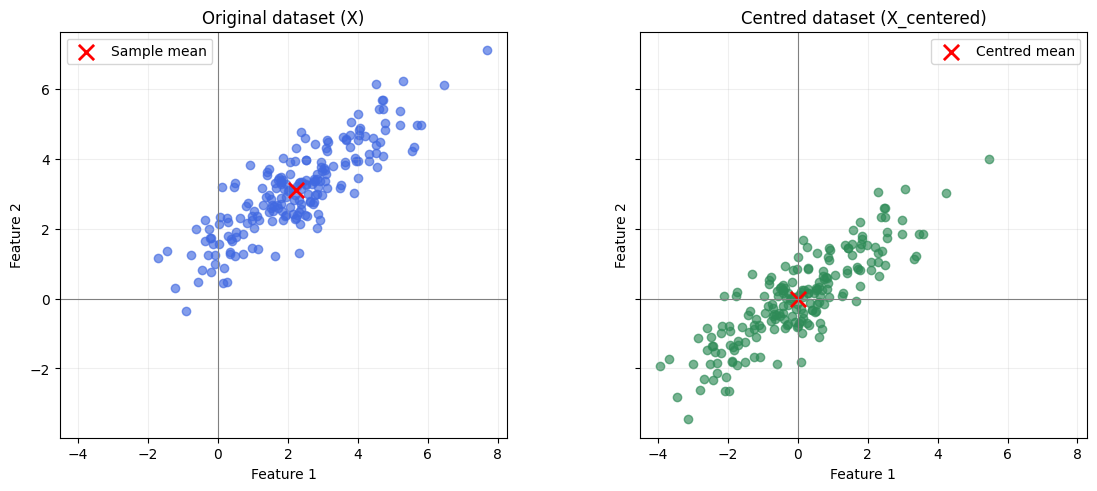

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

# Original data
axes[0].scatter(X[:, 0], X[:, 1], alpha=0.65, color="royalblue")
axes[0].scatter(
    *X.mean(axis=0), # The * unpacks the tuple returned by X.mean(axis=0)
    color="red", marker="x", s=120, linewidths=2,
    label="Sample mean"
)
axes[0].set_title("Original dataset (X)")
axes[0].legend()

# Centred data
axes[1].scatter(
    X_centered[:, 0], X_centered[:, 1],
    alpha=0.65, color="seagreen"
)
axes[1].scatter(
    0, 0,
    color="red", marker="x", s=120, linewidths=2,
    label="Centred mean"
)
axes[1].set_title("Centred dataset (X_centered)")
axes[1].legend()

for ax in axes:
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.axvline(0, color="grey", linewidth=0.8)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.grid(alpha=0.2)
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()


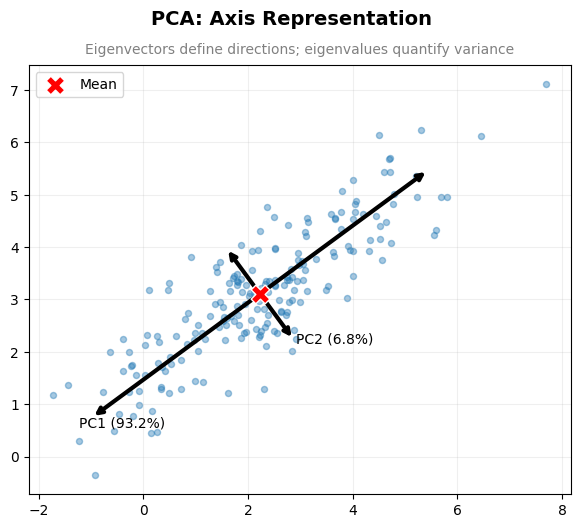

In [19]:
def plot_pca_components(data, eigen_vectors, eigen_values, mode="axis", components=None, figsize=(7, 6), debug_mode=False):
    fig, ax = plt.subplots(figsize=figsize)

    # Plot data points
    ax.scatter(data[:, 0], data[:, 1], alpha=0.40, s=19)

    # Calculate the mean and explained variance ratio
    centre = data.mean(axis=0)
    explained_variance_ratio = eigen_values / eigen_values.sum()

    if components is None:
        components = range(2)

    # Plot principal components
    for i in components:
        direction = eigen_vectors[:, i] * np.sqrt(eigen_values[i]) * 2

        if mode == "axis":
            start = centre - direction
            end = centre + direction
            arrow_style = "<->"

        elif mode == "vector":
            start = centre
            end = centre + direction
            arrow_style = "->"

        else:
            raise ValueError("mode must be 'axis' or 'vector'")

        if debug_mode:
            print(f"Component {i+1}: Start = {start}, End = {end}, Arrow Style = {arrow_style}")

        ax.annotate(
            "",
            xy=end,
            xytext=start,
            arrowprops=dict(arrowstyle=arrow_style, lw=3, zorder=2)
        )

        ax.text(
            *(end + direction * 0.08),
            f"PC{i+1} ({explained_variance_ratio[i]:.1%})"
        )

    # Plot mean
    #ax.scatter(*centre, marker="x", s=95, label="Mean") # With the original code it is not shown properly.
    ax.scatter(
        *centre,
        marker="X",
        s=180,
        color="red",
        edgecolors="white",
        linewidths=1,
        zorder=10,
        label="Mean"
    )

    if debug_mode:
        print(f"Mean: {centre}")

    fig.suptitle(
        f"PCA: {mode.capitalize()} Representation",
        fontsize=14,
        fontweight="bold",
        y=0.98
    )

    ax.set_title(
        "Eigenvectors define directions; eigenvalues quantify variance",
        fontsize=10,
        color="grey",
        pad=8
    )


    # Default layout
    fig.subplots_adjust(top=0.95)

    # Preserve equal scaling
    ax.set_aspect("equal", adjustable="box")

    # Check the actual rendered title positions
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()

    main_title = fig._suptitle.get_window_extent(renderer)
    subtitle = ax.title.get_window_extent(renderer)

    gap = main_title.y0 - subtitle.y1

    # Adjust only when the titles are too close
    if gap < 5:
        fig.subplots_adjust(top=0.90)
        fig.canvas.draw()

    ax.grid(alpha=0.2)
    ax.legend()

    if debug_mode:
        renderer = fig.canvas.get_renderer()
        main_title = fig._suptitle.get_window_extent(renderer)
        subtitle = ax.title.get_window_extent(renderer)

        final_gap = main_title.y0 - subtitle.y1
        print(f"Final title gap: {final_gap:.2f} px")

    plt.show()

    return centre

centre = plot_pca_components(X, X_eigen_vectors, X_eigen_values, mode="axis", debug_mode=False)

## 7. Project the data onto the first principal component

Let $\mathbf V$ be the matrix containing the **eigenvectors of the covariance matrix as columns**, ordered by their corresponding eigenvalues in descending order.

The PCA coordinates are calculated as:

$$
\mathbf Z=(\mathbf X-\bar{\mathbf X})\mathbf V
$$

To reduce the data from two dimensions to one, retain only the **first column of $\mathbf V$**, corresponding to the largest eigenvalue.

This preserves the greatest possible sample variance among all one-dimensional **linear projections** of the centred data.


Original X shape: (200, 2)
Full PCA Z shape: (200, 2)
One-dimensional PCA shape: (200,)
PC1 sample variance: 3.963641677159418
PC1 eigenvalue: 3.9636416771594183
1D explained variance: 93.2%


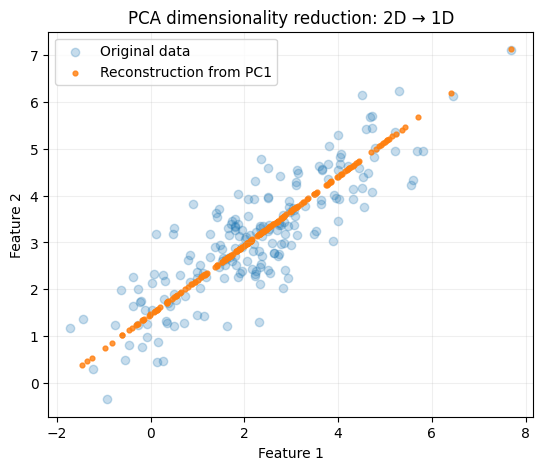

In [20]:
Z = X_centered @ X_eigen_vectors
pc1_scores = Z[:, 0] # All rows, first column of Z
X_reconstructed_1d = np.outer(pc1_scores, X_eigen_vectors[:,0]) + centre

print("Original X shape:", X.shape)
print("Full PCA Z shape:", Z.shape)
print("One-dimensional PCA shape:", pc1_scores.shape)
print("PC1 sample variance:", np.var(pc1_scores, ddof=1))
print("PC1 eigenvalue:", X_eigen_values[0])
print("1D explained variance:", f"{explained_variance_ratio[0]:.1%}")
assert np.isclose(np.var(pc1_scores, ddof=1), X_eigen_values[0])

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X[:,0], X[:,1], alpha=.25, label="Original data")
ax.scatter(X_reconstructed_1d[:,0], X_reconstructed_1d[:,1], s=12,
           alpha=.8, label="Reconstruction from PC1")
ax.set(xlabel="Feature 1", ylabel="Feature 2", title="PCA dimensionality reduction: 2D → 1D")
ax.set_aspect('equal', adjustable='box')
ax.grid(alpha=.2)
ax.legend()
plt.show()

### PCA Projection, Dimensionality Reduction and Reconstruction

The following three lines perform **PCA projection, dimensionality reduction and reconstruction**:

```python
Z = X_centered @ X_eigen_vectors
pc1_scores = Z[:, 0]
X_reconstructed_1d = np.outer(pc1_scores, X_eigen_vectors[:, 0]) + centre
```

The process consists of three stages:

1. **Projection:** Transform the original features into principal component coordinates.
2. **Dimensionality reduction:** Retain only the first principal component (PC1).
3. **Reconstruction:** Approximate the original dataset using only the information retained by PC1.

The key distinction is that **projection changes the coordinate system, dimensionality reduction discards components, and reconstruction returns the reduced data to the original feature space**.

#### 1. Project the centred data onto the principal components

```python
Z = X_centered @ X_eigen_vectors
```

Mathematically:

$$
\boxed{\mathbf Z=\mathbf X_c\mathbf V}
$$

Where:

- $\mathbf X_c$ is the **centred dataset**, obtained by subtracting the mean of each feature.
- $\mathbf V$ is the matrix containing the **eigenvectors of the covariance matrix as columns**, ordered by decreasing eigenvalue.
- $\mathbf Z$ contains the new PCA coordinates, also called **principal component scores**.

The centred dataset is calculated as:

$$
\mathbf X_c=\mathbf X-\bar{\mathbf X}
$$

Here, $\bar{\mathbf X}$ represents the vector of feature means, subtracted from every observation.

##### Numerical example

Consider one centred observation:

$$
\mathbf x_c=
\begin{bmatrix}
2 & 1
\end{bmatrix}
$$

And the following eigenvector matrix:

$$
\mathbf V=
\begin{bmatrix}
0.8 & -0.6\\
0.6 & 0.8
\end{bmatrix}
$$

Each column represents a principal component direction:

$$
\mathbf v_1=
\begin{bmatrix}
0.8\\
0.6
\end{bmatrix}
\qquad
\mathbf v_2=
\begin{bmatrix}
-0.6\\
0.8
\end{bmatrix}
$$

The projection is:

$$
\begin{aligned}
\mathbf z
&=\mathbf x_c\mathbf V\\[6pt]
&=
\begin{bmatrix}
2 & 1
\end{bmatrix}
\begin{bmatrix}
0.8 & -0.6\\
0.6 & 0.8
\end{bmatrix}\\[6pt]
&=
\begin{bmatrix}
2(0.8)+1(0.6) &
2(-0.6)+1(0.8)
\end{bmatrix}\\[6pt]
&=
\boxed{
\begin{bmatrix}
2.2 & -0.4
\end{bmatrix}
}
\end{aligned}
$$

The observation originally had centred coordinates $(2,1)$. In the PCA coordinate system, its coordinates are $(2.2,-0.4)$.

**Important:** At this stage, no dimensionality reduction has occurred. The observation still has two coordinates, but they now describe its position along PC1 and PC2 rather than the original feature axes.

#### 2. Keep only the first principal component

```python
pc1_scores = Z[:, 0]
```

In NumPy:

- `:` selects **all rows**, representing all observations.
- `0` selects the **first column**, representing PC1.

Suppose the projected dataset is:

$$
\mathbf Z=
\begin{bmatrix}
2.2 & -0.4\\
1.5 & 0.2\\
-0.8 & 0.1
\end{bmatrix}
$$

After selecting the first column:

$$
\mathbf z_1=
\begin{bmatrix}
2.2\\
1.5\\
-0.8
\end{bmatrix}
$$

The dataset has now been reduced from **two features to one principal component**.

Each observation is represented by a single number describing its position along the PC1 axis.

For the dataset analysed earlier, PC1 explains approximately **93.18% of the total variance**.

Therefore, retaining PC1 preserves most of the original variability, while discarding PC2 removes approximately 6.82%.

#### 3. Reconstruct the dataset using only PC1

```python
X_reconstructed_1d = np.outer(pc1_scores, X_eigen_vectors[:, 0]) + centre
```

This reconstructs an approximation of the original observations using only their PC1 scores.

The mathematical expression is:

$$
\boxed{
\hat{\mathbf X}
=
\mathbf z_1\mathbf v_1^T+\boldsymbol\mu
}
$$

Where:

- $\hat{\mathbf X}$ is the reconstructed dataset.
- $\mathbf z_1$ contains the PC1 scores for every observation.
- $\mathbf v_1^T$ is the transpose of the first eigenvector.
- $\boldsymbol\mu$ is the vector of original feature means, added to every reconstructed observation.

##### Step 3.1: Extract the first eigenvector

```python
X_eigen_vectors[:, 0]
```

This extracts the first column of the eigenvector matrix:

$$
\mathbf v_1=
\begin{bmatrix}
0.8\\
0.6
\end{bmatrix}
$$

Its transpose is:

$$
\mathbf v_1^T=
\begin{bmatrix}
0.8 & 0.6
\end{bmatrix}
$$

##### Step 3.2: Calculate the outer product

```python
np.outer(pc1_scores, X_eigen_vectors[:, 0])
```

The outer product multiplies every PC1 score by the coordinates of the first eigenvector.

Using our example:

$$
\mathbf z_1=
\begin{bmatrix}
2.2\\
1.5\\
-0.8
\end{bmatrix}
$$

We calculate:

$$
\begin{aligned}
\mathbf z_1\mathbf v_1^T
&=
\begin{bmatrix}
2.2\\
1.5\\
-0.8
\end{bmatrix}
\begin{bmatrix}
0.8 & 0.6
\end{bmatrix}\\[6pt]
&=
\begin{bmatrix}
2.2(0.8) & 2.2(0.6)\\
1.5(0.8) & 1.5(0.6)\\
-0.8(0.8) & -0.8(0.6)
\end{bmatrix}\\[6pt]
&=
\boxed{
\begin{bmatrix}
1.76 & 1.32\\
1.20 & 0.90\\
-0.64 & -0.48
\end{bmatrix}
}
\end{aligned}
$$

We have transformed one score per observation back into two feature coordinates.

However, these coordinates are still **centred around zero**.

##### Step 3.3: Add the original mean

```python
+ centre
```

Remember that PCA was performed on centred data:

```python
centre = X.mean(axis=0)
X_centered = X - centre
```

To reconstruct observations in the original coordinate system, we must add the feature means back.

For example, if:

$$
\boldsymbol\mu=
\begin{bmatrix}
3 & 4
\end{bmatrix}
$$

Then:

$$
\begin{aligned}
\hat{\mathbf X}
&=
\begin{bmatrix}
1.76 & 1.32\\
1.20 & 0.90\\
-0.64 & -0.48
\end{bmatrix}
+
\begin{bmatrix}
3 & 4
\end{bmatrix}\\[6pt]
&=
\boxed{
\begin{bmatrix}
4.76 & 5.32\\
4.20 & 4.90\\
2.36 & 3.52
\end{bmatrix}
}
\end{aligned}
$$

NumPy uses [**broadcasting**](https://numpy.org/doc/2.5/user/basics.broadcasting.html) to add the mean vector to every row.

The reconstructed dataset again has two features, but the observations now lie entirely along the PC1 axis.

#### 4. Visualising projection and reconstruction

![PCA projection and reconstruction using PC1](./images/week_4/projection_and_reconstruction.svg)

The diagram illustrates:

- **Orange points:** Original observations in two-dimensional space.
- **Blue points:** Reconstructed observations using only PC1.
- **Blue line:** First principal component axis.
- **Dashed lines:** The differences between original and reconstructed observations.
- **Mean:** The centre through which the PC1 axis passes.

Each original observation is projected onto the PC1 axis.

Because PC2 has been discarded, the reconstructed points cannot reproduce deviations along the second principal component.

The differences between original and reconstructed observations represent the **reconstruction error**.

#### 5. Dimensionality at each stage

Suppose the original dataset contains 100 observations and two features.

| Python expression | Operation | Shape |
|---|---|---|
| `X_centered` | Original centred dataset | `(100, 2)` |
| `X_eigen_vectors` | Eigenvector matrix | `(2, 2)` |
| `Z` | PCA coordinates | `(100, 2)` |
| `pc1_scores` | Only the PC1 coordinates | `(100,)` |
| `X_reconstructed_1d` | Reconstructed 2D dataset | `(100, 2)` |

The dimensionality changes as follows:

$$
\underbrace{2D}_{\text{Original}}
\;\longrightarrow\;
\underbrace{2D}_{\text{PCA projection}}
\;\longrightarrow\;
\underbrace{1D}_{\text{PC1 only}}
\;\longrightarrow\;
\underbrace{2D}_{\text{Approximate reconstruction}}
$$

Although the final reconstructed dataset contains two features, it still has only **one independent dimension of variation**, because all observations lie along the PC1 axis.

#### 6. Alternative reconstruction using NumPy broadcasting

Instead of:

```python
X_reconstructed_1d = np.outer(
    pc1_scores,
    X_eigen_vectors[:, 0]
) + centre
```

We can use NumPy broadcasting:

```python
X_reconstructed_1d = (
    pc1_scores[:, np.newaxis] * X_eigen_vectors[:, 0]
    + centre
)
```

Here, `np.newaxis` converts the PC1 scores from shape `(n,)` into `(n, 1)`, allowing each score to multiply the corresponding eigenvector coordinates.

Both implementations produce the same result.

#### 7. Key takeaways

- **Projection:** Converts original feature coordinates into principal component coordinates.
- **Dimensionality reduction:** Discards less important principal components, retaining only those explaining the greatest variance.
- **Reconstruction:** Uses the retained component scores and eigenvectors to approximate the original dataset.
- **Mean restoration:** Adds the original feature means back after reconstruction.
- **Information loss:** Discarded components cannot be recovered from the retained scores alone.

**Conclusion:** PCA allows us to represent a dataset using fewer coordinates while preserving as much variance as possible. Reconstructing the data from only PC1 produces the closest one-dimensional linear approximation to the centred dataset in the least-squares sense.


In [21]:
print("Example for the first observation:")
first_row_of_x_centered = X_centered[0]

print(f"First row of X centered: {first_row_of_x_centered}")
print(f"\nEigen vector matrix:\n{X_eigen_vectors}")

manual_1 = first_row_of_x_centered[0]*X_eigen_vectors[0,0] + first_row_of_x_centered[1]*X_eigen_vectors[1,0] # Using the first column of X_eigen_vectors
manual_2 = first_row_of_x_centered[0]*X_eigen_vectors[0,1] + first_row_of_x_centered[1]*X_eigen_vectors[1,1] # Using the second column of X_eigen_vectors
print(f"\nManual values = [{manual_1:.4f}, {manual_2:.4f}]")
multiply_first_and_eigen = first_row_of_x_centered @ X_eigen_vectors

print(f"\nFirst row of X multiplied by eigen vectors:\t{multiply_first_and_eigen}")

print(f"Principal component scores:\t\t\t\t\t{Z[0]}")

print("\nDifference:\t\t", multiply_first_and_eigen - Z[0])
print("Match:\t\t\t", np.allclose(multiply_first_and_eigen, Z[0]))


Example for the first observation:
First row of X centered: [-0.3375  0.029 ]

Eigen vector matrix:
[[-0.8054  0.5928]
 [-0.5928 -0.8054]]

Manual values = [0.2547, -0.2234]

First row of X multiplied by eigen vectors:	[ 0.2547 -0.2234]
Principal component scores:					[ 0.2547 -0.2234]

Difference:		 [0. 0.]
Match:			 True


## 8. Check PCA against scikit-learn (optional)

The preceding calculations require only NumPy. If `scikit-learn` is installed, this cell verifies its `PCA` implementation. Eigenvector signs can differ, so compare their absolute values.

In [22]:
try:
    from sklearn.decomposition import PCA
    pca = PCA(n_components=2)
    pca.fit(X)
    print("scikit-learn eigenvalues:", pca.explained_variance_)
    print("NumPy eigenvalues:       ", X_eigen_values)
    print("scikit-learn explained variance ratios:", pca.explained_variance_ratio_)
    assert np.allclose(pca.explained_variance_, X_eigen_values)
except ImportError:
    print("scikit-learn is not installed; skip this optional verification.")

scikit-learn eigenvalues: [3.9636 0.29  ]
NumPy eigenvalues:        [3.9636 0.29  ]
scikit-learn explained variance ratios: [0.9318 0.0682]


## 9. Quick practice exercises

1. For $X=[2,4,6]$, calculate the **sample variance** manually, then check with NumPy.
2. If $Y=[6,4,2]$, what sign will $\operatorname{Cov}(X,Y)$ have? Why?
3. For $\mathbf A=\left[\begin{smallmatrix}4&0\\0&2\end{smallmatrix}\right]$, identify both eigenvalues and their corresponding eigenvectors.
4. In [Section 6](#section-6), what fraction of the variance does PC1 explain? What happens if you reverse the signs of its eigenvector?
5. Change the data covariance in [Section 6](#section-6) to `[[2, 0], [0, 2]]`. Why might the principal directions now be unstable across samples?

**Bonus:** Try standardising the columns of `X` and comparing its covariance matrix, eigenvectors and explained variance ratios with the unstandardised version.

In [23]:
# Exercise workspace
# Replace these with your own calculations.
practice_x = np.array([2., 4., 6.])
practice_y = np.array([6., 4., 2.])
print("Sample variance of X:", np.var(practice_x, ddof=1))
print("Sample covariance of X and Y:", np.cov(practice_x, practice_y)[0,1])

Sample variance of X: 4.0
Sample covariance of X and Y: -4.0


### Exercices completed

In [24]:
display(Markdown("### Exercice 1"))

n_practice_x = len(practice_x)
mean_practice_x = practice_x.mean()
deviations_practice_x = practice_x - mean_practice_x
squared_deviations_practice_x = deviations_practice_x**2
manual_variance_practice_x = squared_deviations_practice_x.sum() / (n_practice_x - 1)
sample_std_practice_x = np.std(practice_x, ddof=1)

summary = pd.DataFrame({
    "X value": practice_x,
    "Deviation from mean": deviations_practice_x,
    "Squared deviation": squared_deviations_practice_x
})

#display(summary.style.format("{:.0f}"))
display_dataframe(summary)

# Format the observations for LaTeX
values = "+".join(f"{x:g}" for x in practice_x)
deviations_practice_x = "+".join(
    f"({x:g}-{mean_practice_x:g})^2" for x in practice_x
)
squared_deviations_practice_x = "+".join(
    f"{(x - mean_practice_x)**2:g}" for x in practice_x
)

# 1. Mean
display(Math(
    rf"\bar{{x}} = \frac{{{values}}}{{{n_practice_x}}} = {mean_practice_x:.1f}"
))

# 2. Sample variance
display(Math(
    rf"\boxed{{s^2 = \frac{{{deviations_practice_x}}}{{{n_practice_x}-1}}"
    rf" = \frac{{{squared_deviations_practice_x}}}{{{n_practice_x-1}}}"
    rf" = {manual_variance_practice_x:.1f}}}"
))

# 3. NumPy sample variance
display(Math(
    rf"\operatorname{{Var}}_{{\mathrm{{NumPy}}}}(X)"
    rf" = {np.var(practice_x, ddof=1):.1f}"
))

# 4. Sample standard deviation
display(Math(
    rf"s = \sqrt{{s^2}}"
    rf" = \sqrt{{{manual_variance_practice_x:.1f}}}"
    rf" = {sample_std_practice_x:.3f}"
))

### Exercice 1

,X value,Deviation from mean,Squared deviation
0,2,-2,4
1,4,0,0
2,6,2,4


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [25]:
display(Markdown("### Exercice 2"))

n_practice_y = len(practice_y)
mean_practice_y = practice_y.mean()
deviations_practice_y = practice_y - mean_practice_y
squared_deviations_practice_y = deviations_practice_y**2
manual_variance_practice_y = squared_deviations_practice_y.sum() / (n_practice_y - 1)
sample_std_practice_y = np.std(practice_y, ddof=1)

summary = pd.DataFrame({
    "X value": practice_x,
    "Deviation from mean X ": (practice_x - mean_practice_x),
    "Squared deviation X": (practice_x - mean_practice_x)**2,
    "Y value": practice_y,
    "Deviation from mean Y": deviations_practice_y,
    "Squared deviation Y": squared_deviations_practice_y
})

#display(summary.style.format("{:.0f}"))
display_dataframe(summary)

# Format the observations for LaTeX
values = "+".join(f"{x:g}" for x in practice_y)
deviations_practice_y = "+".join(
    f"({x:g}-{mean_practice_y:g})^2" for x in practice_y
)
squared_deviations_practice_y = "+".join(
    f"{(x - mean_practice_y)**2:g}" for x in practice_y
)

# 1. Mean
display(Math(
    rf"\bar{{y}} = \frac{{{values}}}{{{n_practice_y}}} = {mean_practice_y:.1f}"
))

# 2. Sample variance
display(Math(
    rf"s^2 = \frac{{{deviations_practice_y}}}{{{n_practice_y}-1}}"
    rf" = \frac{{{squared_deviations_practice_y}}}{{{n_practice_y-1}}}"
    rf" = {manual_variance_practice_y:.1f}"
))

# 3. NumPy sample variance
display(Math(
    rf"\operatorname{{Var}}_{{\mathrm{{NumPy}}}}(X)"
    rf" = {np.var(practice_y, ddof=1):.1f}"
))

# 4. Sample standard deviation
display(Math(
    rf"s = \sqrt{{s^2}}"
    rf" = \sqrt{{{manual_variance_practice_y:.1f}}}"
    rf" = {sample_std_practice_y:.3f}"
))

# 5. Covariance formula
display(Math(
    rf"\operatorname{{Cov}}(X,Y)=\frac{{1}}{{n-1}}\sum_{{i=1}}^n(x_i-\bar{{x}})(y_i-\bar{{y}})"
))

covariance_terms = " + ".join(
    rf"({h:g}-{mean_practice_x:g})({s:g}-{mean_practice_y:g})"
    for h, s in zip(practice_x, practice_y)
)

covariance_terms_after = " + ".join(
    rf"({(h-mean_practice_x):g})({(s-mean_practice_y):g})"
    for h, s in zip(practice_x, practice_y)
)

display(Math(
    r"\operatorname{Cov}(X,Y)"
    r" = \frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}{n-1}"
))

products = (practice_x - practice_x.mean()) * (practice_y - practice_x.mean())
manual_covariance = products.sum() / (n_practice_x-1)


display(Math(
    rf"\begin{{aligned}}"
    rf"\boxed{{\operatorname{{Cov}}(\mathrm{{hours}},\mathrm{{scores}})}}"
    rf" &= \frac{{{covariance_terms}}}{{{n_practice_x}-1}} \\[6pt]"
    rf" &= \frac{{{covariance_terms_after}}}{{{n_practice_x}-1}}"
    rf" = \frac{{{latex_sum(products)}}}{{{n_practice_x-1}}}"
    rf" = \frac{{{products.sum():g}}}{{{n_practice_x-1}}}"
    rf" = \boxed{{{manual_covariance:g}}}"
    rf"\end{{aligned}}"
))

### Exercice 2

,X value,Deviation from mean X,Squared deviation X,Y value,Deviation from mean Y,Squared deviation Y
0,2,-2,4,6,2,4
1,4,0,0,4,0,0
2,6,2,4,2,-2,4


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [26]:
data = pd.DataFrame({"X": practice_x, "Y": practice_y})
print("Sample covariance matrix:")
display(data.cov())
print("Correlation matrix:")
display(data.corr())
print("np.cov agrees with pandas:\n", np.cov(practice_x, practice_y))
print("np.corrcoef agrees with pandas:\n", np.corrcoef(practice_x, practice_y))

display(Markdown(f"**The covariance value calculated by numpy is {np.cov(practice_x, practice_y)[0,1]:g}**"))

Sample covariance matrix:


,X,Y
X,4.0,-4.0
Y,-4.0,4.0


Correlation matrix:


,X,Y
X,1.0,-1.0
Y,-1.0,1.0


np.cov agrees with pandas:
 [[ 4. -4.]
 [-4.  4.]]
np.corrcoef agrees with pandas:
 [[ 1. -1.]
 [-1.  1.]]


**The covariance value calculated by numpy is -4**

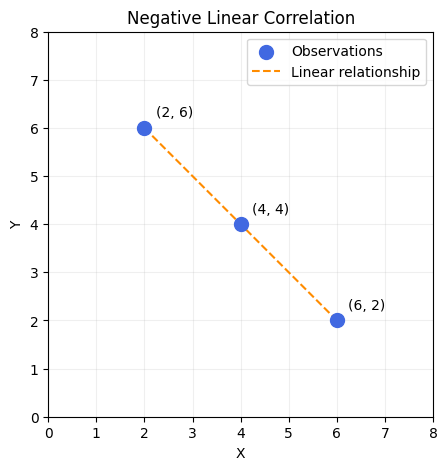

In [27]:
import numpy as np
import matplotlib.pyplot as plt

practice_x = np.array([2., 4., 6.])
practice_y = np.array([6., 4., 2.])

fig, ax = plt.subplots(figsize=(6, 5))

# Plot observations
ax.scatter(
    practice_x, practice_y,
    color="royalblue",
    s=100,
    label="Observations",
    zorder=3
)

# Connect the observations
ax.plot(
    practice_x, practice_y,
    color="darkorange",
    linestyle="--",
    label="Linear relationship"
)

# Label each observation
for x, y in zip(practice_x, practice_y):
    ax.annotate(
        f"({x:g}, {y:g})",
        (x, y),
        xytext=(8, 8),
        textcoords="offset points"
    )

ax.set(
    xlabel="X",
    ylabel="Y",
    title="Negative Linear Correlation"
)

ax.set_xlim(0, 8)
ax.set_ylim(0, 8)
ax.set_aspect("equal")
ax.grid(alpha=0.2)
ax.legend()

plt.show()

The covariance is **negative (-4)** because X and Y move in opposite directions. As X increases, Y decreases, producing a downward-sloping line in the scatter plot.

Mathematically, the deviations from their respective means have opposite signs, resulting in negative products when calculating covariance.

Since the relationship is perfectly linear and decreasing, the Pearson correlation coefficient is **-1**.

### Exercice 3


### Calculating the eigenvalues of a matrix

Given the matrix:

$$
\mathbf{A} =
\begin{bmatrix}
4 & 0 \\
0 & 2
\end{bmatrix}
$$

We want to find the eigenvalues $\lambda$ of $\mathbf{A}$.

#### Step 1: Calculate $\mathbf{A} - \lambda \mathbf{I}$

The identity matrix is:

$$
\mathbf{I} =
\begin{bmatrix}
1 & 0 \\
0 & 1
\end{bmatrix}
$$

Multiplying the identity matrix by $\lambda$:

$$
\lambda \mathbf{I} =
\begin{bmatrix}
\lambda & 0 \\
0 & \lambda
\end{bmatrix}
$$

Subtracting $\lambda \mathbf{I}$ from $\mathbf{A}$:

$$
\mathbf{A} - \lambda \mathbf{I}
=
\begin{bmatrix}
4 & 0 \\
0 & 2
\end{bmatrix}
-
\begin{bmatrix}
\lambda & 0 \\
0 & \lambda
\end{bmatrix}
$$

Therefore:

$$
\boxed{
\mathbf{A} - \lambda \mathbf{I}
=
\begin{bmatrix}
4-\lambda & 0 \\
0 & 2-\lambda
\end{bmatrix}
}
$$

#### Step 2: Compute the determinant

To find the eigenvalues, solve the **characteristic equation**:

$$
\det(\mathbf{A} - \lambda \mathbf{I}) = 0
$$

For a $2 \times 2$ matrix:

$$
\det
\begin{bmatrix}
a & b \\
c & d
\end{bmatrix}
= ad - bc
$$

Applying this formula:

$$
\det
\begin{bmatrix}
4-\lambda & 0 \\
0 & 2-\lambda
\end{bmatrix}
= 0
$$

$$
(4-\lambda)(2-\lambda) - (0 \times 0) = 0
$$

Simplifying:

$$
(4-\lambda)(2-\lambda) = 0
$$

Expanding:

$$
8 - 4\lambda - 2\lambda + \lambda^2 = 0
$$

Rearranging into standard quadratic form:

$$
\boxed{\lambda^2 - 6\lambda + 8 = 0}
$$

#### Step 3: Solve the quadratic equation

We now solve:

$$
\lambda^2 - 6\lambda + 8 = 0
$$

The general quadratic equation is:

$$
ax^2 + bx + c = 0
$$

Its solutions are given by:

$$
x = \frac{-b \pm \sqrt{b^2 - 4ac}}{2a}
$$

In our case:

- $a = 1$
- $b = -6$
- $c = 8$

Substituting:

$$
\lambda =
\frac{-(-6) \pm \sqrt{(-6)^2 - 4(1)(8)}}{2(1)}
$$

Simplifying:

$$
\lambda =
\frac{6 \pm \sqrt{36-32}}{2}
$$

$$
\lambda =
\frac{6 \pm \sqrt{4}}{2}
$$

$$
\lambda =
\frac{6 \pm 2}{2}
$$

**First eigenvalue:**

$$
\lambda_1 = \frac{6+2}{2} = 4
$$

**Second eigenvalue:**

$$
\lambda_2 = \frac{6-2}{2} = 2
$$

Therefore, the eigenvalues are:

$$
\boxed{\lambda_1 = 4 \qquad \lambda_2 = 2}
$$

---

#### Shortcut: Eigenvalues of a diagonal matrix

Our original matrix is:

$$
\mathbf{A} =
\begin{bmatrix}
4 & 0 \\
0 & 2
\end{bmatrix}
$$

This is a **diagonal matrix**, meaning all elements outside the main diagonal are zero.

For any diagonal matrix:

$$
\mathbf{D} =
\begin{bmatrix}
d_1 & 0 & 0 \\
0 & d_2 & 0 \\
0 & 0 & d_3
\end{bmatrix}
$$

The eigenvalues are simply its diagonal elements:

$$
\lambda_1 = d_1, \qquad
\lambda_2 = d_2, \qquad
\lambda_3 = d_3
$$

Therefore, for our matrix:

$$
\boxed{\lambda_1 = 4 \qquad \lambda_2 = 2}
$$

**Key takeaway:** For a diagonal matrix, you can read the eigenvalues directly from the main diagonal without calculating the determinant or solving a quadratic equation.

This shortcut applies to diagonal matrices of any size.


### Calculating the eigenvectors of a matrix

Given the matrix:

$$
\mathbf{A} =
\begin{bmatrix}
4 & 0 \\
0 & 2
\end{bmatrix}
$$

We have already calculated its eigenvalues:

$$
\lambda_1 = 4, \qquad \lambda_2 = 2
$$

Now we need to find the **eigenvector corresponding to each eigenvalue**.

#### Step 1: The eigenvector equation

An eigenvector $\mathbf{v}$ satisfies:

$$
\mathbf{A}\mathbf{v} = \lambda\mathbf{v}
$$

Rearranging:

$$
\mathbf{A}\mathbf{v} - \lambda\mathbf{v} = 0
$$

Factoring out $\mathbf{v}$ using the identity matrix:

$$
\boxed{(\mathbf{A} - \lambda\mathbf{I})\mathbf{v} = \mathbf{0}}
$$

For a $2 \times 2$ matrix, the eigenvector has two components:

$$
\mathbf{v} =
\begin{bmatrix}
x \\
y
\end{bmatrix}
$$

We solve this equation separately for each eigenvalue.

---

#### Step 2: Find the eigenvector for $\lambda_1 = 4$

Substitute $\lambda_1 = 4$:

$$
(\mathbf{A} - 4\mathbf{I})\mathbf{v}_1 = \mathbf{0}
$$

Expanding:

$$
\left(
\begin{bmatrix}
4 & 0 \\
0 & 2
\end{bmatrix}
-
\begin{bmatrix}
4 & 0 \\
0 & 4
\end{bmatrix}
\right)
\begin{bmatrix}
x \\
y
\end{bmatrix}
=
\begin{bmatrix}
0 \\
0
\end{bmatrix}
$$

Subtracting the matrices:

$$
\begin{bmatrix}
0 & 0 \\
0 & -2
\end{bmatrix}
\begin{bmatrix}
x \\
y
\end{bmatrix}
=
\begin{bmatrix}
0 \\
0
\end{bmatrix}
$$

Multiplying the matrix by the vector gives two equations:

$$
\begin{cases}
0x + 0y = 0 \\
0x - 2y = 0
\end{cases}
$$

From the second equation:

$$
-2y = 0 \implies y = 0
$$

The first equation is always satisfied, meaning **$x$ can be any real number except zero**.

We can choose $x = 1$ for simplicity.

Therefore:

$$
\boxed{
\mathbf{v}_1 =
\begin{bmatrix}
1 \\
0
\end{bmatrix}
}
$$

Any nonzero scalar multiple of this vector is also an eigenvector:

$$
\mathbf{v}_1 =
\begin{bmatrix}
t \\
0
\end{bmatrix},
\qquad t \neq 0
$$

#### Step 3: Find the eigenvector for $\lambda_2 = 2$

Substitute $\lambda_2 = 2$:

$$
(\mathbf{A} - 2\mathbf{I})\mathbf{v}_2 = \mathbf{0}
$$

Expanding:

$$
\left(
\begin{bmatrix}
4 & 0 \\
0 & 2
\end{bmatrix}
-
\begin{bmatrix}
2 & 0 \\
0 & 2
\end{bmatrix}
\right)
\begin{bmatrix}
x \\
y
\end{bmatrix}
=
\begin{bmatrix}
0 \\
0
\end{bmatrix}
$$

Subtracting the matrices:

$$
\begin{bmatrix}
2 & 0 \\
0 & 0
\end{bmatrix}
\begin{bmatrix}
x \\
y
\end{bmatrix}
=
\begin{bmatrix}
0 \\
0
\end{bmatrix}
$$

Multiplying the matrix by the vector gives:

$$
\begin{cases}
2x + 0y = 0 \\
0x + 0y = 0
\end{cases}
$$

From the first equation:

$$
2x = 0 \implies x = 0
$$

The second equation is always satisfied, meaning **$y$ can be any real number except zero**.

We can choose $y = 1$ for simplicity.

Therefore:

$$
\boxed{
\mathbf{v}_2 =
\begin{bmatrix}
0 \\
1
\end{bmatrix}
}
$$

Any nonzero scalar multiple is also an eigenvector:

$$
\mathbf{v}_2 =
\begin{bmatrix}
0 \\
t
\end{bmatrix},
\qquad t \neq 0
$$

---

#### Step 4: Verify the results

We can verify each eigenvector using:

$$
\mathbf{A}\mathbf{v} = \lambda\mathbf{v}
$$

**For $\lambda_1 = 4$:**

$$
\begin{bmatrix}
4 & 0 \\
0 & 2
\end{bmatrix}
\begin{bmatrix}
1 \\
0
\end{bmatrix}
=
\begin{bmatrix}
4 \\
0
\end{bmatrix}
=
4
\begin{bmatrix}
1 \\
0
\end{bmatrix}
$$

The equation is satisfied.

**For $\lambda_2 = 2$:**

$$
\begin{bmatrix}
4 & 0 \\
0 & 2
\end{bmatrix}
\begin{bmatrix}
0 \\
1
\end{bmatrix}
=
\begin{bmatrix}
0 \\
2
\end{bmatrix}
=
2
\begin{bmatrix}
0 \\
1
\end{bmatrix}
$$

The equation is also satisfied.

#### Addendum: Why can we choose any nonzero value?

An eigenvector satisfies:

$$
A\mathbf{v} = \lambda\mathbf{v}
$$

The eigenvalue is the **factor by which the vector is scaled**, not a coordinate of the resulting vector.

For example, instead of choosing $x = 1$, choose $x = 3$:

$$
A =
\begin{bmatrix}
4 & 0 \\
0 & 2
\end{bmatrix},
\qquad
\mathbf{v} =
\begin{bmatrix}
3 \\
0
\end{bmatrix}
$$

Multiplying:

$$
A\mathbf{v}
=
\begin{bmatrix}
12 \\
0
\end{bmatrix}
=
4
\begin{bmatrix}
3 \\
0
\end{bmatrix}
=
4\mathbf{v}
$$

The eigenvalue is still **4**, not 12: the original coordinate was 3
and became 12, so the scaling factor is $12/3 = 4$.

More generally, for any $t \neq 0$:

$$
A
\begin{bmatrix}
t \\
0
\end{bmatrix}
=
\begin{bmatrix}
4t \\
0
\end{bmatrix}
=
4
\begin{bmatrix}
t \\
0
\end{bmatrix}
$$

Similarly, for the eigenvalue $\lambda = 2$:

$$
A
\begin{bmatrix}
0 \\
t
\end{bmatrix}
=
\begin{bmatrix}
0 \\
2t
\end{bmatrix}
=
2
\begin{bmatrix}
0 \\
t
\end{bmatrix}
$$

Therefore, choosing a different nonzero value changes the eigenvector's
length, and possibly its orientation along the same line, but **does not
change its eigenvalue**.

We choose $t = 1$ for convenience: it gives a vector of length 1.
We exclude $t = 0$ because the zero vector is not an eigenvector.

#### Final results

The eigenvalues and their corresponding eigenvectors are:

$$
\boxed{
\lambda_1 = 4
\quad \longrightarrow \quad
\mathbf{v}_1 =
\begin{bmatrix}
1 \\
0
\end{bmatrix}
}
$$

$$
\boxed{
\lambda_2 = 2
\quad \longrightarrow \quad
\mathbf{v}_2 =
\begin{bmatrix}
0 \\
1
\end{bmatrix}
}
$$

---

#### Shortcut: Eigenvectors of a diagonal matrix

For a diagonal matrix with **distinct diagonal values**, each eigenvalue corresponds to a standard basis vector.

For our matrix:

$$
\mathbf{A} =
\begin{bmatrix}
4 & 0 \\
0 & 2
\end{bmatrix}
$$

- The first diagonal element, $4$, corresponds to the horizontal direction $\begin{bmatrix}1\\0\end{bmatrix}$.
- The second diagonal element, $2$, corresponds to the vertical direction $\begin{bmatrix}0\\1\end{bmatrix}$.

**Geometric interpretation:**

The matrix $\mathbf{A}$ transforms vectors by:

- Stretching the horizontal ($x$) direction by a factor of **4**.
- Stretching the vertical ($y$) direction by a factor of **2**.

The eigenvectors identify directions that remain unchanged under the transformation, while the eigenvalues indicate how much vectors along those directions are scaled.

**Important:** Eigenvectors must be nonzero vectors, but they do not need to have length 1. For diagonal matrices with repeated eigenvalues, the corresponding eigenvectors are not restricted to individual standard basis vectors.


In [28]:
A = np.array([[4, 0], [0, 2]])

# Calculate eigenvalues and eigenvectors directly
values_A, vectors_A = np.linalg.eigh(A)

# Sort eigenvalues in descending order
order_A = np.argsort(values_A)[::-1]
values_A = values_A[order_A]
vectors_A = vectors_A[:, order_A]

print("Eigenvalues (descending):", values_A)
print("Eigenvectors (columns):\n", vectors_A)

# Verify A @ v = lambda * v
# np.diag(values_A) converts the eigenvalues into a diagonal matrix
assert np.allclose(A @ vectors_A, vectors_A @ np.diag(values_A))

# plot_pca_components(A, vectors_A, values_A, mode="vector")

Eigenvalues (descending): [4. 2.]
Eigenvectors (columns):
 [[1. 0.]
 [0. 1.]]


### Exercice 4

**Part 1: What fraction of the variance does PC1 explain?**

The first PCA component captures 93.2% of the variance.

**Part 2: What happens if you reverse the signs of its eigenvector?**

If I reverse the value of the first eigenvector

The original eigenvectors are:

$$\left[\begin{matrix}-0.805383657416694\\-0.592753881780718\end{matrix}\right]$$

We extract the first eigenvector (the most relevant, as it has the largest eigenvalue).

The negative of the first eigenvector is:

$$\left[\begin{matrix}0.805383657416694\\0.592753881780718\end{matrix}\right]$$

The new eigenmatrix is $$\left[\begin{matrix}0.805383657416694 & 0.592753881780718\\0.592753881780718 & -0.805383657416694\end{matrix}\right]$$

**Original eigenvectors**

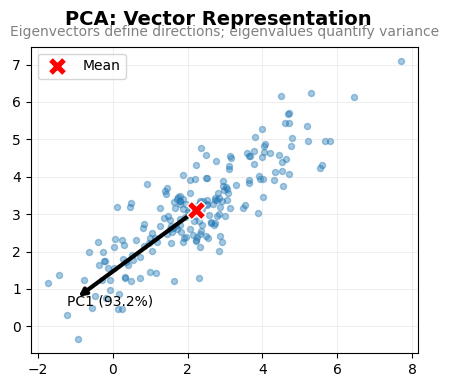

**Reversed eigenvectors**

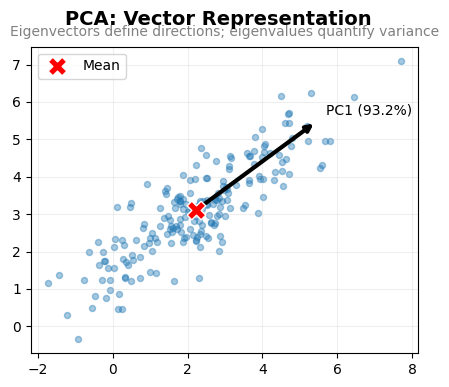

The first PCA component captures 93.2% of the variance.
If I reverse the value of the first eigenvector, the variance captured remains the same.

PC1 scores reverse sign: True


In [29]:
# In [Section 6](#section-6), what fraction of the variance does PC1 explain? What happens if you reverse the signs of its eigenvector?
display(Markdown("### Exercice 4"))

display(Markdown(f"**Part 1: What fraction of the variance does PC1 explain?**\n\nThe first PCA component captures {explained_variance_ratio[0]:.1%} of the variance.\n\n**Part 2: What happens if you reverse the signs of its eigenvector?**\n\nIf I reverse the value of the first eigenvector"))

#first_eigen_vector = X_eigen_vectors[:, 0]
#first_eigen_vector_negative = -first_eigen_vector
#new_eigen_matrix = np.column_stack((first_eigen_vector_negative, X_eigen_vectors[:, 1:]))
new_eigen_vectors = np.column_stack((
    -X_eigen_vectors[:, 0], # The negative of the first eigenvector
    X_eigen_vectors[:, 1:] # The second eigenvector remains the same
))

display(Markdown(
    f"The original eigenvectors are:\n\n"
    f"$${latex(Matrix(X_eigen_vectors[:, 0]))}$$\n\n"
    f"We extract the first eigenvector (the most relevant, as it has the largest eigenvalue).\n\n"
    f"The negative of the first eigenvector is:\n\n"
    f"$${latex(Matrix(-X_eigen_vectors[:, 0]))}$$\n\n"
    f"The new eigenmatrix is $${latex(Matrix(new_eigen_vectors))}$$"
))

new_smaller_size = (5, 4) # To fit 2 in one page
display(Markdown("**Original eigenvectors**"))
plot_pca_components(X, X_eigen_vectors, X_eigen_values,
              mode="vector", components=[0],
              figsize=new_smaller_size,
)

display(Markdown("**Reversed eigenvectors**"))
plot_pca_components(X, new_eigen_vectors, X_eigen_values,
              mode="vector", components=[0],
              figsize=new_smaller_size,
)

display(Markdown(f"The first PCA component captures {explained_variance_ratio[0]:.1%} of the variance.\nIf I reverse the value of the first eigenvector, the variance captured remains the same."))

original_scores = X_centered @ X_eigen_vectors[:, 0]
reversed_scores = X_centered @ new_eigen_vectors[:, 0]

assert np.allclose(reversed_scores, -original_scores)
print("PC1 scores reverse sign:", np.allclose(reversed_scores, -original_scores))


### Conclusions exercise 4

**Part 1: What fraction of the variance does PC1 explain?**

The first principal component (PC1) explains the proportion of total variance given by its eigenvalue divided by the sum of all eigenvalues:

$$
\text{Explained Variance Ratio}_{PC1}
=
\frac{\lambda_1}{\sum_{i=1}^{n}\lambda_i}
$$

**Part 2: What happens if you reverse the sign of its eigenvector?**

Reversing the sign of the first eigenvector does not change the variance explained by PC1 or its principal axis. It only reverses the orientation of the eigenvector and the signs of the corresponding PCA scores.

The visual effect depends on the plotting mode:

- **Axis mode (`<->`):** The plot remains identical because the principal component is represented by a double-headed arrow. Reversing the eigenvector simply swaps the endpoints.
- **Vector mode (`->`):** The arrow points in the opposite direction, making the sign reversal visible. However, its length and the variance explained remain unchanged.

**Conclusion:** Eigenvector signs are arbitrary in PCA. Both $\mathbf{v}$ and $-\mathbf{v}$ represent the same principal component axis and explain the same amount of variance.


In [30]:
# 5. Change the data covariance in [Section 6](#section-6) to `[[2, 0], [0, 2]]`. Why might the principal directions now be unstable across samples?
display(Markdown("### Exercice 5"))
S_modified = np.array([[2, 0], [0, 2]])

# eigh returns eigenvalues in ascending order.
modified_eigenvalues, modified_eigenvectors = np.linalg.eigh(S_modified)

modified_order = np.argsort(modified_eigenvalues)[::-1]
modified_eigenvalues = modified_eigenvalues[modified_order]
modified_eigenvectors = modified_eigenvectors[:, modified_order]

modified_explained_variance_ratio = (
    modified_eigenvalues / modified_eigenvalues.sum()
)

print("Means:", X.mean(axis=0)) # axis=0 (Column-wise). Collapses the rows vertically, calculating the mean of each column.
print("Covariance matrix:\n", S_modified)
print("Eigenvalues (descending):", modified_eigenvalues)
print("Eigenvectors (columns):\n", modified_eigenvectors)
print("Explained variance ratios:", modified_explained_variance_ratio)
print(
    "Total variance = trace(S_modified) = sum(eigenvalues):",
    np.trace(S_modified),
    modified_eigenvalues.sum(),
)

assert np.allclose(
    S_modified @ modified_eigenvectors,
    modified_eigenvectors @ np.diag(modified_eigenvalues),
)

### Exercice 5

Means: [2.2273 3.1063]
Covariance matrix:
 [[2 0]
 [0 2]]
Eigenvalues (descending): [2. 2.]
Eigenvectors (columns):
 [[0. 1.]
 [1. 0.]]
Explained variance ratios: [0.5 0.5]
Total variance = trace(S_modified) = sum(eigenvalues): 4 4.0



### Exercise 5 solution

**What happens when the covariance matrix is changed to $\begin{bmatrix}2&0\\0&2\end{bmatrix}$? Why might the principal directions be unstable across samples?**

Both eigenvalues are equal:

$$
\lambda_1=\lambda_2=2
$$

Therefore, each principal component explains the same proportion of the total variance:

$$
\frac{2}{2+2}=50\%
$$

Since the covariance matrix is a multiple of the identity matrix ($S=2I$), every nonzero vector is an eigenvector. Consequently, there is no uniquely preferred principal direction.

Note: for this exercise $I = \begin{bmatrix}1&0\\0&1\end{bmatrix}$ and $S = \begin{bmatrix}2&0\\0&2\end{bmatrix}$. Therefore $S=2I$

Small differences between samples can produce slightly different covariance matrices, causing the principal component directions to change significantly.

**Conclusion:** PCA remains mathematically valid, but it cannot identify a unique dominant direction. Reducing the dataset from two dimensions to one would retain only 50% of its variance, regardless of the chosen direction.


In [31]:
# StandardScaler() uses the population standard deviation (ddof=0), while the covariance calculation in this notebook uses ddof=1. Therefore, the resulting sample variances will be \(n/(n-1)\), not exactly 1.
use_standard_scaler_bool = False

display(Markdown("### Bonus exercise"))

# Original dataset
S_original = np.cov(X, rowvar=False, ddof=1)
values_original, vectors_original = np.linalg.eigh(S_original)

if use_standard_scaler_bool:
    from sklearn.preprocessing import StandardScaler

    # Standardise each column
    scaler = StandardScaler()
    X_standardised = scaler.fit_transform(X) # Internally this uses ddof=0
else:
    X_standardised = (X - X.mean(axis=0)) / X.std(axis=0, ddof=1)

# Calculate the new covariance matrix
S_standardised = np.cov(X_standardised, rowvar=False, ddof=1)
values_standardised, vectors_standardised = np.linalg.eigh(S_standardised)

# Sort both sets of eigenvalues and eigenvectors
order_original = np.argsort(values_original)[::-1]
values_original = values_original[order_original]
vectors_original = vectors_original[:, order_original]

order_standardised = np.argsort(values_standardised)[::-1]
values_standardised = values_standardised[order_standardised]
vectors_standardised = vectors_standardised[:, order_standardised]

# Explained variance ratios
ratio_original = values_original / values_original.sum()
ratio_standardised = values_standardised / values_standardised.sum()

print("Original covariance matrix:\n", S_original)
print("Standardised covariance matrix:\n", S_standardised)

print("\nOriginal eigenvalues:", values_original)
print("Standardised eigenvalues:", values_standardised)

print("\nOriginal eigenvectors:\n", vectors_original)
print("Standardised eigenvectors:\n", vectors_standardised)

print("\nOriginal explained variance ratios:", ratio_original)
print("Standardised explained variance ratios:", ratio_standardised)


### Bonus exercise

Original covariance matrix:
 [[2.6729 1.7538]
 [1.7538 1.5808]]
Standardised covariance matrix:
 [[1.     0.8532]
 [0.8532 1.    ]]

Original eigenvalues: [3.9636 0.29  ]
Standardised eigenvalues: [1.8532 0.1468]

Original eigenvectors:
 [[-0.8054  0.5928]
 [-0.5928 -0.8054]]
Standardised eigenvectors:
 [[ 0.7071 -0.7071]
 [ 0.7071  0.7071]]

Original explained variance ratios: [0.9318 0.0682]
Standardised explained variance ratios: [0.9266 0.0734]


**Original eigenvectors**

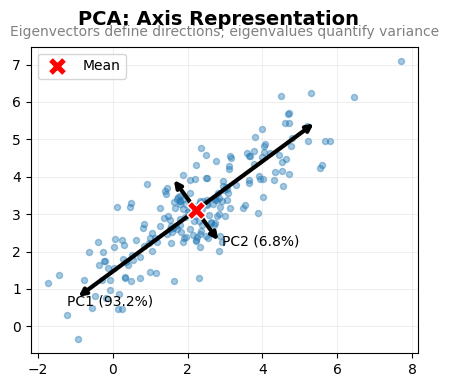

**Standardised eigenvectors**

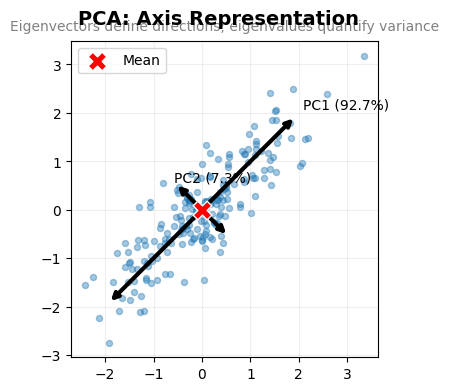

In [32]:
display(Markdown("**Original eigenvectors**"))
centre = plot_pca_components(
    X, vectors_original, values_original,
    mode="axis",
    debug_mode=False,
    figsize=new_smaller_size
)

display(Markdown("**Standardised eigenvectors**"))
centre =  plot_pca_components(
    X_standardised, vectors_standardised, values_standardised,
    mode="axis",
    debug_mode=False,
    figsize=new_smaller_size
)


### Bonus: Effect of Standardisation on PCA

After standardising the columns of `X`, I observed the following changes:

- **Covariance matrix:** The diagonal elements changed to 1, since both features now have unit variance.
- **Eigenvalues:** They changed from approximately $[3.9636,\ 0.2900]$ to $[1.8532,\ 0.1468]$.
- **Eigenvectors:** The principal directions rotated because both features now contribute equally in terms of their individual variances.
- **Explained variance ratios:** PC1 decreased slightly from **93.18% to 92.66%**, a difference of only **0.52 percentage points**.

The standardised covariance matrix also reveals a strong positive correlation between the two features:

$$
\rho = 0.8532
$$

**Conclusion:** Standardisation produced only a modest rotation of the principal component directions (approximately 8.7°) and a small reduction in the variance explained by PC1 (0.52 percentage points). This suggests that the original differences in feature scales had a relatively limited effect on the PCA results. Both before and after standardisation, PC1 captures approximately 93% of the total variance.

This demonstrates that standardisation can change PCA results, although the effect depends on the original variance and correlation structure of the dataset.



# Relationship Between Covariance, Eigenvectors and PCA

There is an important relationship between **eigenvectors and covariance**, particularly in Principal Component Analysis (PCA).

The key distinctions are:

- **Covariance** describes how variables vary together.
- **Eigenvectors** of the covariance matrix identify the principal directions in which the data varies.
- **Eigenvalues** quantify how much variance exists along each of those directions.

## 1. What does the covariance matrix tell us?

For a dataset with two features, $X$ and $Y$, the covariance matrix is:

$$
S =
\begin{bmatrix}
\operatorname{Var}(X) & \operatorname{Cov}(X,Y) \\
\operatorname{Cov}(X,Y) & \operatorname{Var}(Y)
\end{bmatrix}
$$

It contains two kinds of information:

- **Diagonal elements:** The variance of each feature.
- **Off-diagonal elements:** How the features vary together.

For example:

$$
S =
\begin{bmatrix}
4 & 2 \\
2 & 4
\end{bmatrix}
$$

This tells us that:

- Both features have a variance of $4$.
- Their covariance is positive ($2$).
- The features tend to increase and decrease together.

However, the covariance matrix does not directly identify the directions of maximum and minimum variance. That is where **eigenvectors** become useful.

## 2. What do eigenvectors tell us about covariance?

When we calculate the eigenvectors of a covariance matrix, we identify new directions along which the data varies.

Consider:

$$
S =
\begin{bmatrix}
4 & 2 \\
2 & 4
\end{bmatrix}
$$

Its eigenvalues and corresponding unit eigenvectors are:

**First principal component (PC1):**

$$
\lambda_1 = 6,
\qquad
\mathbf{v}_1 =
\frac{1}{\sqrt{2}}
\begin{bmatrix}
1 \\
1
\end{bmatrix}
$$

**Second principal component (PC2):**

$$
\lambda_2 = 2,
\qquad
\mathbf{v}_2 =
\frac{1}{\sqrt{2}}
\begin{bmatrix}
1 \\
-1
\end{bmatrix}
$$

### Addendum: Calculating the eigenvalues step by step

Given the covariance matrix:

$$
S =
\begin{bmatrix}
4 & 2 \\
2 & 4
\end{bmatrix}
$$

The eigenvalues satisfy the **characteristic equation**:

$$
\det(S-\lambda I)=0
$$

#### Step 1: Subtract $\lambda I$

$$
S-\lambda I =
\begin{bmatrix}
4-\lambda & 2 \\
2 & 4-\lambda
\end{bmatrix}
$$

#### Step 2: Calculate the determinant

For a $2\times2$ matrix:

$$
\det
\begin{bmatrix}
a & b \\
c & d
\end{bmatrix}
=ad-bc
$$

Therefore:

$$
\det(S-\lambda I)
=
(4-\lambda)(4-\lambda)-(2)(2)
$$

Setting this equal to zero:

$$
(4-\lambda)^2-4=0
$$

#### Step 3: Solve for $\lambda$

$$
(4-\lambda)^2=4
$$

Taking square roots gives both possibilities:

$$
4-\lambda=\pm2
$$

Thus:

- If $4-\lambda=2$, then $\lambda=2$.
- If $4-\lambda=-2$, then $\lambda=6$.

Ordering the eigenvalues from largest to smallest:

$$
\boxed{\lambda_1=6,\qquad\lambda_2=2}
$$

#### Alternative: Using the quadratic formula

Expanding the characteristic equation:

$$
(4-\lambda)^2-4
=
16-8\lambda+\lambda^2-4
=
\lambda^2-8\lambda+12
$$

We therefore solve:

$$
\lambda^2-8\lambda+12=0
$$

Using $a=1$, $b=-8$, and $c=12$:

$$
\lambda
=
\frac{-b\pm\sqrt{b^2-4ac}}{2a}
=
\frac{8\pm\sqrt{64-48}}{2}
=
\frac{8\pm\sqrt{16}}{2}
=
\frac{8\pm4}{2}
$$

Hence:

$$
\boxed{\lambda_1=6,\qquad\lambda_2=2}
$$

**Arithmetic check:** The discriminant is $64-48=16$, and the
denominator divides both terms in the numerator:

$$
\frac{8\pm4}{2}
=
\frac{8}{2}\pm\frac{4}{2}
=
4\pm2
$$

#### Step 4: Verify using the eigenvectors

An eigenvalue and its eigenvector must satisfy:

$$
S\mathbf{v}=\lambda\mathbf{v}
$$

For the first unit eigenvector:

$$
S\left(
\frac{1}{\sqrt{2}}
\begin{bmatrix}
1\\
1
\end{bmatrix}
\right)
=
\frac{1}{\sqrt{2}}
\begin{bmatrix}
6\\
6
\end{bmatrix}
=
6\left(
\frac{1}{\sqrt{2}}
\begin{bmatrix}
1\\
1
\end{bmatrix}
\right)
$$

For the second unit eigenvector:

$$
S\left(
\frac{1}{\sqrt{2}}
\begin{bmatrix}
1\\
-1
\end{bmatrix}
\right)
=
\frac{1}{\sqrt{2}}
\begin{bmatrix}
2\\
-2
\end{bmatrix}
=
2\left(
\frac{1}{\sqrt{2}}
\begin{bmatrix}
1\\
-1
\end{bmatrix}
\right)
$$

Both eigenvalues are confirmed.

Because $S$ is a covariance matrix, these eigenvalues represent the
variances along the corresponding unit principal directions:

- **PC1:** variance of $6$.
- **PC2:** variance of $2$.

### Addendum: Calculating the eigenvectors step by step

Given the covariance matrix:

$$
S =
\begin{bmatrix}
4 & 2 \\
2 & 4
\end{bmatrix}
$$

We have already calculated its eigenvalues:

$$
\lambda_1=6,\qquad\lambda_2=2
$$

An eigenvector is a **nonzero vector** satisfying:

$$
S\mathbf{v}=\lambda\mathbf{v}
$$

Equivalently:

$$
(S-\lambda I)\mathbf{v}=\mathbf{0}
$$

Write the unknown vector as:

$$
\mathbf{v}=
\begin{bmatrix}
x\\
y
\end{bmatrix}
$$

#### Step 1: Find an eigenvector for $\lambda_1=6$

Substitute $\lambda_1=6$:

$$
S-6I=
\begin{bmatrix}
-2 & 2\\
2 & -2
\end{bmatrix}
$$

Therefore:

$$
\begin{bmatrix}
-2 & 2\\
2 & -2
\end{bmatrix}
\begin{bmatrix}
x\\
y
\end{bmatrix}
=
\begin{bmatrix}
0\\
0
\end{bmatrix}
$$

This gives:

$$
\begin{cases}
-2x+2y=0\\
2x-2y=0
\end{cases}
$$

Both equations express the same condition:

$$
y=x
$$

Thus, every eigenvector associated with $\lambda_1=6$ has the form:

$$
\mathbf{v}=
t\begin{bmatrix}
1\\
1
\end{bmatrix},
\qquad t\neq0
$$

Choosing $t=1$ gives:

$$
\mathbf{u}_1=
\begin{bmatrix}
1\\
1
\end{bmatrix}
$$

#### Step 2: Normalize the first eigenvector

For PCA, we use eigenvectors of length 1.

The length of $\mathbf{u}_1$ is:

$$
\|\mathbf{u}_1\|
=
\sqrt{1^2+1^2}
=
\sqrt{2}
$$

Divide the vector by its length:

$$
\boxed{
\mathbf{v}_1
=
\frac{\mathbf{u}_1}{\|\mathbf{u}_1\|}
=
\frac{1}{\sqrt{2}}
\begin{bmatrix}
1\\
1
\end{bmatrix}
}
$$

This is the direction of the first principal component, PC1.

#### Step 3: Find an eigenvector for $\lambda_2=2$

Substitute $\lambda_2=2$:

$$
S-2I=
\begin{bmatrix}
2 & 2\\
2 & 2
\end{bmatrix}
$$

Therefore:

$$
\begin{bmatrix}
2 & 2\\
2 & 2
\end{bmatrix}
\begin{bmatrix}
x\\
y
\end{bmatrix}
=
\begin{bmatrix}
0\\
0
\end{bmatrix}
$$

This gives:

$$
\begin{cases}
2x+2y=0\\
2x+2y=0
\end{cases}
$$

Both equations imply:

$$
y=-x
$$

Thus, every eigenvector associated with $\lambda_2=2$ has the form:

$$
\mathbf{v}=
t\begin{bmatrix}
1\\
-1
\end{bmatrix},
\qquad t\neq0
$$

Choosing $t=1$ gives:

$$
\mathbf{u}_2=
\begin{bmatrix}
1\\
-1
\end{bmatrix}
$$

#### Step 4: Normalize the second eigenvector

Its length is:

$$
\|\mathbf{u}_2\|
=
\sqrt{1^2+(-1)^2}
=
\sqrt{2}
$$

Therefore:

$$
\boxed{
\mathbf{v}_2
=
\frac{\mathbf{u}_2}{\|\mathbf{u}_2\|}
=
\frac{1}{\sqrt{2}}
\begin{bmatrix}
1\\
-1
\end{bmatrix}
}
$$

This is the direction of the second principal component, PC2.

#### Step 5: Check that the directions are perpendicular

The dot product of the unit eigenvectors is:

$$
\mathbf{v}_1^\mathsf{T}\mathbf{v}_2
=
\frac{1}{2}\left(1\cdot1+1\cdot(-1)\right)
=
0
$$

A zero dot product means the directions are perpendicular.

#### Final result

The eigenvalues and corresponding unit eigenvectors are:

$$
\boxed{
\lambda_1=6,
\qquad
\mathbf{v}_1=
\frac{1}{\sqrt{2}}
\begin{bmatrix}
1\\
1
\end{bmatrix}
}
$$

$$
\boxed{
\lambda_2=2,
\qquad
\mathbf{v}_2=
\frac{1}{\sqrt{2}}
\begin{bmatrix}
1\\
-1
\end{bmatrix}
}
$$

PC1 follows the line $y=x$, along which the variance is 6.
PC2 follows the line $y=-x$, along which the variance is 2.

**Sign convention:** Multiplying either eigenvector by $-1$ gives an
equally valid unit eigenvector with the same eigenvalue. It reverses
the arrow along the same principal axis.

### Visualising the principal component directions

![Covariance and PCA principal component directions](./images/week_4/covariance_and_pca.svg)

The diagram illustrates that:

- **PC1** follows the diagonal where both features increase together.
- **PC2** follows the perpendicular diagonal where one feature increases as the other decreases.
- **PC1 has the larger eigenvalue**, so more variance lies along its direction.

The eigenvectors effectively **rotate the coordinate system** to align with the natural directions of variation in the dataset.

### Explained variance ratios

The proportion of total variance explained by each principal component is:

$$
\operatorname{EVR}_i =
\frac{\lambda_i}{\sum_{j=1}^{n}\lambda_j}
$$

For PC1:

$$
\operatorname{EVR}_1 =
\frac{6}{6+2}
= 0.75 = 75\%
$$

For PC2:

$$
\operatorname{EVR}_2 =
\frac{2}{6+2}
= 0.25 = 25\%
$$

Therefore, **PC1 captures 75% of the total variance**, while PC2 captures the remaining 25%.

## 3. The mathematical relationship

The eigenvalue equation for a covariance matrix is:

$$
S\mathbf{v}_i = \lambda_i\mathbf{v}_i
$$

Where:

- $S$ is the covariance matrix.
- $\mathbf{v}_i$ is an eigenvector.
- $\lambda_i$ is its corresponding eigenvalue.

For a **unit eigenvector** $\mathbf{v}_i$, the variance of the data projected onto that direction is:

$$
\boxed{
\operatorname{Var}(X_c\mathbf{v}_i)
=
\mathbf{v}_i^T S\mathbf{v}_i
=
\lambda_i
}
$$

Where $X_c$ is the centred dataset.

This gives us the fundamental relationship:

**The eigenvalue of a covariance matrix equals the variance of the data projected along its corresponding unit eigenvector.**

### Why does PCA remove covariance between components?

Because covariance matrices are symmetric, their eigenvectors can be chosen to be orthonormal.

If we collect these eigenvectors into a matrix $V$, the covariance matrix in the new coordinate system becomes:

$$
\boxed{
V^T S V = \Lambda
}
$$

Where $\Lambda$ is a diagonal matrix containing the eigenvalues:

$$
\Lambda =
\begin{bmatrix}
\lambda_1 & 0 \\
0 & \lambda_2
\end{bmatrix}
$$

For our example:

$$
\Lambda =
\begin{bmatrix}
6 & 0 \\
0 & 2
\end{bmatrix}
$$

Notice that the **off-diagonal elements are zero**.

This means:

- The principal components are uncorrelated.
- Each principal component captures variance along a different, perpendicular direction.
- PCA transforms correlated features into uncorrelated principal components.

## 4. Connecting this to Exercise 5

In Exercise 5, we modified the covariance matrix to:

$$
S =
\begin{bmatrix}
2 & 0 \\
0 & 2
\end{bmatrix}
$$

This matrix is a multiple of the identity matrix:

$$
S = 2I
$$

Both eigenvalues are equal:

$$
\lambda_1 = \lambda_2 = 2
$$

Therefore, the explained variance ratio for each component is:

$$
\operatorname{EVR}_1 =
\operatorname{EVR}_2 =
\frac{2}{2+2}
= 50\%
$$

### Why are the principal directions unstable?

For any nonzero vector $\mathbf{v}$:

$$
S\mathbf{v} = 2I\mathbf{v} = 2\mathbf{v}
$$

Therefore, **every nonzero vector is an eigenvector with eigenvalue $2$**.

Consequently:

- There is no uniquely preferred principal direction.
- Every unit direction has the same projected variance.
- Small differences between samples can change which directions PCA identifies as PC1 and PC2.
- Reducing from two dimensions to one retains only 50% of the total variance, regardless of the selected direction.

This situation is called **eigenvalue degeneracy**, where repeated eigenvalues prevent the individual eigenvector directions from being uniquely determined.

## 5. Key takeaways

| Concept | Relationship to PCA |
|---|---|
| Variance | Measures the spread of an individual feature |
| Covariance | Measures how two features vary together |
| Covariance matrix | Describes the variance and covariance structure of the dataset |
| Eigenvectors | Identify orthogonal directions of variation |
| Eigenvalues | Quantify variance along the corresponding unit eigenvectors |
| Principal components | New, uncorrelated coordinates obtained by projecting onto the eigenvectors |
| Explained variance ratio | Measures the fraction of total variance captured by each component |
| Equal eigenvalues | Indicate that the associated individual principal directions are not uniquely determined |

### Conclusion

**Covariance describes the spread and relationships of the original features. Eigenvectors of the covariance matrix identify the principal directions of that spread, while their eigenvalues quantify the variance along those directions.**

Eigenvectors are a general linear algebra concept. Their specific relationship to data variance arises when we calculate the eigenvectors of a **covariance matrix**, rather than an arbitrary matrix.

When eigenvalues are distinct, the corresponding principal directions are uniquely determined up to sign. When eigenvalues are repeated, the associated principal directions may not be uniquely determined.


## 10. Summary for your notes

| Concept | Key question | Key fact |
|---|---|---|
| **Variance** | How much does one feature vary? | Non-negative; measured in squared units |
| **Covariance** | How do two features vary together? | Sign shows direction of linear co-movement |
| **Correlation** | How strongly do two variables move linearly together? | Standardised covariance in $[-1,1]$ |
| **Eigenvector** | Which directions remain on the same line after a matrix transform? | Satisfies $A\mathbf v=\lambda\mathbf v$ |
| **Eigenvalue** | By what factor does a matrix scale an eigenvector? | For covariance matrices, equals variance along a unit eigenvector |
| **PCA** | Which axes capture the most variance? | Eigenvectors of covariance matrix, ordered by eigenvalues |

**Practical note:** PCA is not a clustering method. It is an unsupervised dimensionality-reduction method that may be used before clustering algorithms such as DBSCAN or K-means.